<h1 style="color:#003366;">NOVA IMS | MSc in Information Management</h1>
<h2 style="color:#006699;">Data Mining 2025/2026</h2>

<hr style="border:1px solid #006699;">

<h3><b>Group Project:</b> “Predicting Donor Response to Optimize Outreach for Social Good”</h3>
<p><b>Notebook:</b> <i>Data Preprocessing, Modelling and Open-ended Section</i></p>

<h3>Group 19</h3>
<ul>
  <li><b>Filipa Brito</b> – 202211807</li>
  <li><b>Divna Kostova</b> – 20251803</li>
  <li><b>Inês Santos</b> – 20250252</li>
  <li><b>Rita Silva</b> – 20221920</li>
</ul>

### <font color='#006699'>Table of Contents </font> <a class="anchor" id='top'></a> 
- [0. Notebook Explanation](#0-notebook-explanation)
- [1. Imports](#p1)  
- [2. Data Cleaning](#p2) 
  - [2.1 Numerical Features](#p2-1)
  - [2.2 Categorical Features](#p2-2)  
  - [2.3 Rounding ](#p2-3)
  - [2.4 Columns Inconsistencies ](#p2-4)
- [3. Data Partition](#p3)   
- [4. Preprocessing](#p4)  
  - [4.1 Outliers](#p4-1)
  - [4.2 Missing Values](#p4-2)
  - [4.3 Encoding](#p4-3) 
  - [4.4 Feature Engineering](#p4-4)
  - [4.5 Scaling](#p4-5)  
  - [4.6 Feature Selection](#p4-6)
- [5. Modelling](#p5) 
  - [5.1 Model Selection](#p5-1)
  - [5.2 Model Optimization](#p5-2) 
  - [5.3 Threshold Tuning](#p5-3) 
- [6. Deployment](#p6) 
- [7. Open-ended Section](#p7) 
  - [7.1 Confusion Matrix and Classification Report](#p7-1)
  - [7.2 Comparison of Feature Distribution](#p7-2) 

<h1 id="0-notebook-explanation" style="color:#006699;">0. Notebook Explanation</h1>


This notebook's goal is to create and evaluate predictive models that can identify possible donors using a variety of demographic, behavioral, and donation-related characteristics. The work directly expands upon the results of the earlier exploratory data analysis, converting those insights into specific choices at every stage of the modeling process.

Data preparation takes up a significant portion of the notebook. In addition to common tasks like dealing with missing values, handling outliers, encoding categorical variables, and applying feature scaling, special attention was given to making sure related features were logically consistent and to creating new variables that could summarize the donor's behavior over time. To avoid information leaking, reference statistics were only learnt from the training partition, and all modifications were made to be repeatable on unobserved observations.

The modeling step investigates a wide variety of algorithms, including multiple ensemble strategies, tree-based techniques, distance and probability-based approaches, and linear classifiers. Because of the significant class imbalance in the target variable, F1 Score was the score considered as the main criterion. Hyperparameter optimization and classification threshold tuning are then used to refine the most promising setups.

<h1 id="p1" style="color:#006699;">1. Imports</h1>

This section includes the import of the main libraries used throughout the notebook to support data manipulation, visualization, and preprocessing. Pandas and NumPy were used for data handling and numerical operations, while Matplotlib, Seaborn, and Plotly supported the exploratory data analysis through visualizations.

Additionally, preprocessing tools from scikit-learn were imported for tasks such as missing value imputation, categorical encoding, scaling, and dataset splitting.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.graph_objects as go

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_validate,
    cross_val_score,
    cross_val_predict,
    GridSearchCV
)

from sklearn.preprocessing import (
    OrdinalEncoder,
    OneHotEncoder,
    RobustScaler
)

from sklearn.impute import (
    KNNImputer,
    SimpleImputer
)

from sklearn.feature_selection import (
    VarianceThreshold,
    RFE
)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
    PrecisionRecallDisplay,
    RocCurveDisplay
)

from sklearn.dummy import DummyClassifier

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC

from sklearn.ensemble import (
    RandomForestClassifier,
    AdaBoostClassifier,
    BaggingClassifier,
    StackingClassifier
)

from sklearn.metrics import confusion_matrix, classification_report

import warnings
warnings.filterwarnings('ignore')
pd.set_option("display.max_columns", None)

The `pd.read_csv()` function is used to import the dataset into a Pandas DataFrame, providing a structured starting point for the analysis. `CONTROL_NUMBER` is set as the index, as it serves as the unique identifier of each potential donor across the dataset.

In [2]:
data_path = os.path.join('data', 'donors_train.csv')
donors_train  = pd.read_csv(data_path, sep=',')
train = donors_train.copy()
train.head()

,CONTROL_NUMBER,CARD_PROM_12,CHILDREN,DONOR_AGE,DONOR_GENDER,FILE_CARD_GIFT,FREQUENCY_STATUS_97NK,HOME_OWNER,INCOME_GROUP,LAST_GIFT_AMT,LIFETIME_CARD_PROM,LIFETIME_GIFT_AMOUNT,LIFETIME_GIFT_COUNT,LIFETIME_MAX_GIFT_AMT,LIFETIME_MIN_GIFT_AMT,LIFETIME_PROM,MEDIAN_HOME_VALUE,MEDIAN_HOUSEHOLD_INCOME,MONTHS_SINCE_FIRST_GIFT,MONTHS_SINCE_LAST_GIFT,MONTHS_SINCE_LAST_PROM_RESP,NUMBER_PROM_12,PCT_ATTRIBUTE1,PCT_ATTRIBUTE2,PCT_ATTRIBUTE3,PCT_ATTRIBUTE4,PCT_OWNER_OCCUPIED,PEP_STAR,PER_CAPITA_INCOME,RECENCY_STATUS_96NK,RECENT_AVG_CARD_GIFT_AMT,RECENT_AVG_GIFT_AMT,RECENT_CARD_RESPONSE_COUNT,RECENT_CARD_RESPONSE_PROP,RECENT_RESPONSE_COUNT,RECENT_RESPONSE_PROP,RECENT_STAR_STATUS,SES,URBANICITY,WEALTH_RATING,TARGET_B
0,61745,4.0,3.0,33.0,M,0.0,1.0,H,5.0,20.0,9.0,35.0,2.0,20.0,15.0,21.0,566.0,315.0,182.037132,18.0,18.0,10.0,0.0,52.0,17.0,25.0,92.0,0.0,12827.0,A,0.00,17.50,NaN,0.000,2.0,0.154,0.0,2,T,NaN,1
1,112703,3.0,2.0,NaN,F,1.0,1.0,U,NaN,15.0,6.0,15.0,1.0,15.0,15.0,15.0,318.0,148.0,24.000000,24.0,24.0,7.0,0.0,31.0,31.0,39.0,73.0,0.0,7787.0,N,15.00,15.00,1.0,0.250,1.0,0.100,0.0,3,R,NaN,1
2,166437,4.0,2.0,NaN,F,7.0,3.0,H,4.0,10.0,17.0,79.0,11.0,12.0,5.0,40.0,1669.0,373.0,129.000000,15.0,15.0,8.0,0.0,26.0,39.0,38.0,84.0,1.0,13965.0,S,0.00,10.67,0.0,0.000,3.0,0.231,1.0,1,U,NaN,0
3,170621,4.0,NaN,61.0,M,13.0,1.0,H,6.0,11.0,28.0,80.0,17.0,11.0,3.0,75.0,1464.0,488.0,130.000000,16.0,16.0,13.0,0.0,48.0,30.0,44.0,84.0,1.0,24123.0,A,10.00,10.00,2.0,0.286,2.0,0.111,0.0,1,U,NaN,0
4,44428,6.0,0.0,75.0,M,3.0,4.0,H,3.0,7.0,9.0,27.0,5.0,7.0,5.0,22.0,936.0,249.0,24.000000,17.0,17.0,13.0,0.0,52.0,NaN,66.0,90.0,1.0,15008.0,N,5.67,5.40,3.0,0.600,5.0,0.500,0.0,2,C,NaN,0


In [3]:
donors_train.set_index('CONTROL_NUMBER', inplace = True)

<h1 id="p2" style="color:#006699;">2. Data Cleaning</h1>

In this section, the main objective is to clean and prepare the dataset by addressing the inconsistencies identified during the exploratory data analysis (EDA) phase across both numerical and categorical variables.

Data cleaning is an essential step in the modeling process, as inconsistencies, invalid values, and missing information can negatively impact the model’s ability to learn meaningful patterns and generate reliable predictions. Therefore, appropriate preprocessing techniques were applied to improve data quality and ensure the dataset was suitable for the subsequent modeling stages.


In [4]:
# Inspecting unique values per column to detect inconsistencies
for col in donors_train.columns:
    print(f"--- {col} ---")
    print(donors_train[col].unique())
    print()

--- CARD_PROM_12 ---
[ 4.          3.          6.          5.          7.                 nan
  2.         11.          8.         10.          9.          2.12720717
  1.          9.16670817 17.         14.         12.         15.
 13.        ]

--- CHILDREN ---
[ 3.          2.                 nan  0.          4.          1.
 -2.29982422  6.22052627]

--- DONOR_AGE ---
[ 33.                  nan  61.          75.          51.
  40.          69.          57.          68.          79.
  45.          87.          24.          56.          17.
  37.          72.          53.          35.          46.
  83.          71.          34.          50.          67.
  38.          49.          47.          85.          48.
  39.          78.          58.          54.          27.
  25.          29.          41.          80.          66.
  65.          52.          77.          60.          36.
  82.           8.66330425  55.          73.          86.
  64.          31.          59.          63.  

<h3 id = "p2-1" style="color:#006699;">2.1 Numerical Features</h3> <a class="anchor" id="p3-1"></a>

Several correction were applied to the numerical variables in order to address inconsistencies identified during the exploratory data analysis phase (EDA):
- All negative values were replaced with missing values (NaN), since features related to donations, promotions, income and counts should not contain negative observations.
- The `DONOR_AGE` feature was validated to ensure realistic age values. Observations with ages under 18 years old were replaced with missing values.
- Invalid values in `INCOME_GROUP` greater than 7 were replaced with missing values, since the variable only allows categories between 1 and 7.
- Invalid values in `WEALTH_RATING` greater than 9 were replaced with missing values to maintain consistency with the expected rating scale.
- Values above 100 in `PCT_OWNER_OCCUPIED` were replaced with missing values, as percentage cannot exceed 100%.
- Invalid values greater than 1 in the binary variable `PEP_STAR` were replaced with missing values to preserve the expected binary structure of the feature.

These corrections aimed to improve data quality and ensure greater consistency within the numerical variables before proceeding to preprocessing and modeling.

In [5]:
def clean_numeric(df):
    """
    Clean numerical features: out-of-range values become NaN.
    Robust to missing columns (works even if some columns were already dropped).
    """

    # Negative values to NaN (excluding TARGET_B if present)
    num_cols = df.select_dtypes(include="number").columns.tolist()
    if "TARGET_B" in num_cols:
        num_cols.remove("TARGET_B")
    for col in num_cols:
        df.loc[df[col] < 0, col] = np.nan

    # Out-of-range values to NaN — only if column exists
    if "DONOR_AGE" in df.columns:
        df.loc[df["DONOR_AGE"] < 18, "DONOR_AGE"] = np.nan
    if "INCOME_GROUP" in df.columns:
        df.loc[df["INCOME_GROUP"] > 7, "INCOME_GROUP"] = np.nan
    if "WEALTH_RATING" in df.columns:
        df.loc[df["WEALTH_RATING"] > 9, "WEALTH_RATING"] = np.nan
    if "PCT_OWNER_OCCUPIED" in df.columns:
        df.loc[df["PCT_OWNER_OCCUPIED"] > 100, "PCT_OWNER_OCCUPIED"] = np.nan
    if "PEP_STAR" in df.columns:
        df.loc[df["PEP_STAR"] > 1, "PEP_STAR"] = np.nan

    return df

In [6]:
donors_train = clean_numeric(donors_train)

<h3 id = "p2-2" style="color:#006699;">2.2 Categorical Features</h3> <a class="anchor" id="p3-1"></a>

The categorical features were also cleaned to address inconsistencies identified during the EDA phase.

While the EDA phase identified specific inconsistencies (such as `"U"` in `DONOR_GENDER` and `"?"` in `URBANICITY` and `SES`), the cleaning function was designed to be more comprehensive. Rather than replacing only the known invalid values, we adopted a strict approach where any value outside the set of valid categories is converted to NaN. This ensures the pipeline remains robust if the test set contains unexpected values not observed during EDA on the training set.

- `DONOR_GENDER`: any value other than `"F"` or `"M"` is replaced with NaN. This is stricter than only handling the `"U"` category — it also catches any other unexpected entries (e.g. `"A"`) that may appear in the test set.
- `URBANICITY`: any value other than `"C"`, `"R"`, `"S"`, `"T"`, or `"U"` is replaced with NaN, again as a defensive measure against unforeseen categories.
- `SES`: any value other than `"1"`, `"2"`, `"3"`, or `"4"` is replaced with NaN, following the same principle.
- Regarding the variable `RECENT_STAR_STATUS`, the description provided in the dataset documentation appears ambiguous. Based on the observed values, it was assumed that the variable may represent the number of times an individual achieved STAR donor status within the last four years, rather than a simple binary indicator.

In [7]:
def clean_categorical(df):
    if "DONOR_GENDER" in df.columns:
        df["DONOR_GENDER"] = df["DONOR_GENDER"].where(df["DONOR_GENDER"].isin(["F", "M"]), np.nan)
    if "URBANICITY" in df.columns:
        df["URBANICITY"] = df["URBANICITY"].where(df["URBANICITY"].isin(["C", "R", "S", "T", "U"]), np.nan)
    if "SES" in df.columns:
        df["SES"] = df["SES"].where(df["SES"].isin(["1", "2", "3", "4", "5"]), np.nan)
    return df

In [8]:
donors_train = clean_categorical(donors_train)

<h3 id = "p2-3" style="color:#006699;">2.3 Rounding</h3> <a class="anchor" id="p3-1"></a>

Several numerical variables containing unrealistic decimal values were standardized to improve data consistency and readability before the preprocessing stage.

- Several numerical variables expected to contain integer values, such as `DONOR_AGE`, `CHILDREN`, `INCOME_GROUP`, `WEALTH_RATING`, and promotion features, were rounded to remove unexpected decimal observations.
- Variables associated with monetary values, percentages, and proportions, such as `LAST_GIFT_AMT`, `LIFETIME_GIFT_AMOUNT`, `PER_CAPITA_INCOME`, and `RECENT_RESPONSE_PROP`, were rounded to two decimal places.

In [9]:
round_cols = ["DONOR_AGE", "CARD_PROM_12", "NUMBER_PROM_12", "CHILDREN",
              "MONTHS_SINCE_FIRST_GIFT", "MONTHS_SINCE_LAST_GIFT", "LIFETIME_GIFT_COUNT",
              "LIFETIME_CARD_PROM", "LIFETIME_PROM", "MONTHS_SINCE_LAST_PROM_RESP",
              "RECENT_CARD_RESPONSE_COUNT", "RECENT_RESPONSE_COUNT", "INCOME_GROUP",
              "WEALTH_RATING", "FREQUENCY_STATUS_97NK", "RECENT_STAR_STATUS"]

cols_2dec = ["FILE_CARD_GIFT", "LAST_GIFT_AMT", "LIFETIME_GIFT_AMOUNT", "LIFETIME_MAX_GIFT_AMT",
             "LIFETIME_MIN_GIFT_AMT", "MEDIAN_HOUSEHOLD_INCOME", "PCT_ATTRIBUTE1", "PCT_ATTRIBUTE2",
             "PCT_ATTRIBUTE3", "PCT_ATTRIBUTE4", "PCT_OWNER_OCCUPIED", "PER_CAPITA_INCOME",
             "RECENT_AVG_CARD_GIFT_AMT", "RECENT_AVG_GIFT_AMT", "RECENT_CARD_RESPONSE_PROP",
             "RECENT_RESPONSE_PROP", "MEDIAN_HOME_VALUE"]


def round_values(df):
    df[round_cols] = df[round_cols].round()
    df[cols_2dec] = df[cols_2dec].round(2)
    return df

In [10]:
donors_train = round_values(donors_train)

<h3 id = "p2-4" style="color:#006699;">2.4 Columns Inconsistencies</h3> <a class="anchor" id="p3-1"></a>

In addition to correcting individual invalid values, several consistency checks were performed between related variables to identify logical contradictions within the dataset. These inconsistencies mainly involved donation amounts, response counts, promotion variables, and temporal relationships. Whenever contradictory information was detected, the affected observations were either corrected, replaced with missing values (NaN), or removed when appropriate, in order to preserve the reliability and consistency of the dataset before the modeling stage.

To approach this, we first identified all the inconsistencies between columns that could not logically co-occur. Each pair (or group) of related variables was analyzed individually to understand the underlying cause of the contradiction and to define the most appropriate corrective action. After this exploratory stage, all the detected inconsistencies were consilidated into a single function, which includes the full set of corrections in a structured manner. This design choice was intentional, by centralising the logic in one function, so that the same pre-processing steps can be effortlessly applied to the test set, ensuring consistency between the two partitions and preventing any form of data leakage.

<h4><b>2.4.1 Donation Amount Inconsistencies</b></h4>

<b style="color:#006699;"> LIFETIME_MIN_GIFT_AMT vs LIFETIME_MAX_GIFT_AMT </b>

The minimum lifetime donation amount should never be greater than the maximum lifetime donation amount. 

The inconsistency encountered was associated with the repeated value 31.63 in `LIFETIME_MIN_GIFT_AMT`. The fact that this exact value appears across multiple observations strongly suggests a corrupted or incorrectly recorded entry, making it highly unlikely that 31.63 represents the true minimum donation amount for all those donors. For this reason, the affected observations were replaced with missing values (NaN) rather than adjusted to match the maximum donation amount.

In [12]:
donors_train[donors_train['LIFETIME_MIN_GIFT_AMT'] > donors_train['LIFETIME_MAX_GIFT_AMT']]

,CARD_PROM_12,CHILDREN,DONOR_AGE,DONOR_GENDER,FILE_CARD_GIFT,FREQUENCY_STATUS_97NK,HOME_OWNER,INCOME_GROUP,LAST_GIFT_AMT,LIFETIME_CARD_PROM,LIFETIME_GIFT_AMOUNT,LIFETIME_GIFT_COUNT,LIFETIME_MAX_GIFT_AMT,LIFETIME_MIN_GIFT_AMT,LIFETIME_PROM,MEDIAN_HOME_VALUE,MEDIAN_HOUSEHOLD_INCOME,MONTHS_SINCE_FIRST_GIFT,MONTHS_SINCE_LAST_GIFT,MONTHS_SINCE_LAST_PROM_RESP,NUMBER_PROM_12,PCT_ATTRIBUTE1,PCT_ATTRIBUTE2,PCT_ATTRIBUTE3,PCT_ATTRIBUTE4,PCT_OWNER_OCCUPIED,PEP_STAR,PER_CAPITA_INCOME,RECENCY_STATUS_96NK,RECENT_AVG_CARD_GIFT_AMT,RECENT_AVG_GIFT_AMT,RECENT_CARD_RESPONSE_COUNT,RECENT_CARD_RESPONSE_PROP,RECENT_RESPONSE_COUNT,RECENT_RESPONSE_PROP,RECENT_STAR_STATUS,SES,URBANICITY,WEALTH_RATING,TARGET_B
CONTROL_NUMBER,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
140492,5.0,4.0,NaN,M,12.0,1.0,H,5.0,20.0,31.0,249.0,21.0,20.0,31.63,76.0,714.0,397.0,126.0,26.0,26.0,10.0,0.0,36.0,34.0,30.0,90.0,1.0,15502.0,A,0.00,20.00,0.0,0.00,1.0,0.05,12.0,1,T,8.0,0
54441,6.0,0.0,56.0,F,5.0,1.0,H,4.0,25.0,23.0,102.0,8.0,25.0,31.63,60.0,463.0,181.0,85.0,17.0,17.0,13.0,0.0,20.0,25.0,27.0,84.0,NaN,8369.0,A,0.00,25.00,0.0,0.00,1.0,0.05,15.0,3,R,4.0,1
1970,6.0,2.0,NaN,F,11.0,2.0,U,6.0,10.0,31.0,80.0,16.0,10.0,31.63,74.0,680.0,408.0,102.0,17.0,17.0,15.0,0.0,27.0,32.0,21.0,90.0,1.0,14304.0,A,6.75,6.17,4.0,0.36,6.0,0.27,0.0,2,T,NaN,0
87405,4.0,0.0,NaN,F,1.0,1.0,U,5.0,15.0,10.0,20.0,2.0,15.0,31.63,23.0,666.0,179.0,33.0,26.0,26.0,9.0,0.0,37.0,29.0,NaN,33.0,0.0,11208.0,A,5.00,10.00,1.0,0.14,2.0,0.12,0.0,2,R,NaN,0
29069,6.0,0.0,NaN,F,2.0,3.0,H,3.0,10.0,11.0,44.0,5.0,12.0,31.63,28.0,539.0,224.0,32.0,15.0,15.0,14.0,0.0,26.0,31.0,34.0,84.0,1.0,9594.0,S,9.50,8.80,2.0,0.29,5.0,0.31,1.0,2,R,NaN,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
69445,4.0,4.0,40.0,M,1.0,1.0,H,7.0,20.0,6.0,20.0,1.0,20.0,31.63,15.0,1472.0,532.0,21.0,21.0,21.0,10.0,0.0,31.0,42.0,21.0,97.0,0.0,20135.0,F,20.00,20.00,1.0,0.33,1.0,0.14,0.0,1,T,NaN,1
62626,6.0,3.0,NaN,F,6.0,3.0,U,NaN,10.0,21.0,149.0,13.0,15.0,31.63,56.0,469.0,238.0,67.0,18.0,21.0,13.0,NaN,23.0,27.0,37.0,66.0,1.0,10125.0,S,12.00,12.00,2.0,0.22,2.0,0.10,1.0,NaN,T,4.0,0
186567,5.0,2.0,NaN,NaN,4.0,1.0,U,NaN,5.0,23.0,74.0,10.0,15.0,31.63,59.0,972.0,149.0,109.0,8.0,16.0,15.0,0.0,0.0,0.0,0.0,22.0,NaN,9734.0,A,15.00,NaN,1.0,0.20,1.0,0.08,0.0,NaN,NaN,0.0,0


<b style="color:#006699;"> LIFETIME_MIN_GIFT_AMT vs LAST_GIFT_AMT </b>

The most recent donation amount `LAST_GIFT_AMT` cannot be smaller than the minimum lifetime donation amount `LIFETIME_MIN_GIFT_AMT`. The inconsistent observations were associated with a repeated value 31.63 in the column `LIFETIME_MIN_GIFT_AMT`, which was considered likely corrupted and replaced with missing values.

In [13]:
donors_train[donors_train['LAST_GIFT_AMT'] < donors_train['LIFETIME_MIN_GIFT_AMT']]

,CARD_PROM_12,CHILDREN,DONOR_AGE,DONOR_GENDER,FILE_CARD_GIFT,FREQUENCY_STATUS_97NK,HOME_OWNER,INCOME_GROUP,LAST_GIFT_AMT,LIFETIME_CARD_PROM,LIFETIME_GIFT_AMOUNT,LIFETIME_GIFT_COUNT,LIFETIME_MAX_GIFT_AMT,LIFETIME_MIN_GIFT_AMT,LIFETIME_PROM,MEDIAN_HOME_VALUE,MEDIAN_HOUSEHOLD_INCOME,MONTHS_SINCE_FIRST_GIFT,MONTHS_SINCE_LAST_GIFT,MONTHS_SINCE_LAST_PROM_RESP,NUMBER_PROM_12,PCT_ATTRIBUTE1,PCT_ATTRIBUTE2,PCT_ATTRIBUTE3,PCT_ATTRIBUTE4,PCT_OWNER_OCCUPIED,PEP_STAR,PER_CAPITA_INCOME,RECENCY_STATUS_96NK,RECENT_AVG_CARD_GIFT_AMT,RECENT_AVG_GIFT_AMT,RECENT_CARD_RESPONSE_COUNT,RECENT_CARD_RESPONSE_PROP,RECENT_RESPONSE_COUNT,RECENT_RESPONSE_PROP,RECENT_STAR_STATUS,SES,URBANICITY,WEALTH_RATING,TARGET_B
CONTROL_NUMBER,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
140492,5.0,4.0,NaN,M,12.0,1.0,H,5.0,20.0,31.0,249.0,21.0,20.0,31.63,76.0,714.0,397.0,126.0,26.0,26.0,10.0,0.0,36.0,34.0,30.0,90.0,1.0,15502.0,A,0.00,20.00,0.0,0.00,1.0,0.05,12.0,1,T,8.0,0
54441,6.0,0.0,56.0,F,5.0,1.0,H,4.0,25.0,23.0,102.0,8.0,25.0,31.63,60.0,463.0,181.0,85.0,17.0,17.0,13.0,0.0,20.0,25.0,27.0,84.0,NaN,8369.0,A,0.00,25.00,0.0,0.00,1.0,0.05,15.0,3,R,4.0,1
1970,6.0,2.0,NaN,F,11.0,2.0,U,6.0,10.0,31.0,80.0,16.0,10.0,31.63,74.0,680.0,408.0,102.0,17.0,17.0,15.0,0.0,27.0,32.0,21.0,90.0,1.0,14304.0,A,6.75,6.17,4.0,0.36,6.0,0.27,0.0,2,T,NaN,0
87405,4.0,0.0,NaN,F,1.0,1.0,U,5.0,15.0,10.0,20.0,2.0,15.0,31.63,23.0,666.0,179.0,33.0,26.0,26.0,9.0,0.0,37.0,29.0,NaN,33.0,0.0,11208.0,A,5.00,10.00,1.0,0.14,2.0,0.12,0.0,2,R,NaN,0
29069,6.0,0.0,NaN,F,2.0,3.0,H,3.0,10.0,11.0,44.0,5.0,12.0,31.63,28.0,539.0,224.0,32.0,15.0,15.0,14.0,0.0,26.0,31.0,34.0,84.0,1.0,9594.0,S,9.50,8.80,2.0,0.29,5.0,0.31,1.0,2,R,NaN,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
69445,4.0,4.0,40.0,M,1.0,1.0,H,7.0,20.0,6.0,20.0,1.0,20.0,31.63,15.0,1472.0,532.0,21.0,21.0,21.0,10.0,0.0,31.0,42.0,21.0,97.0,0.0,20135.0,F,20.00,20.00,1.0,0.33,1.0,0.14,0.0,1,T,NaN,1
62626,6.0,3.0,NaN,F,6.0,3.0,U,NaN,10.0,21.0,149.0,13.0,15.0,31.63,56.0,469.0,238.0,67.0,18.0,21.0,13.0,NaN,23.0,27.0,37.0,66.0,1.0,10125.0,S,12.00,12.00,2.0,0.22,2.0,0.10,1.0,NaN,T,4.0,0
186567,5.0,2.0,NaN,NaN,4.0,1.0,U,NaN,5.0,23.0,74.0,10.0,15.0,31.63,59.0,972.0,149.0,109.0,8.0,16.0,15.0,0.0,0.0,0.0,0.0,22.0,NaN,9734.0,A,15.00,NaN,1.0,0.20,1.0,0.08,0.0,NaN,NaN,0.0,0


<b style="color:#006699;"> LIFETIME_MAX_GIFT_AMT vs LAST_GIFT_AMT </b>

The most recent donation amount `LAST_GIFT_AMT` should not exceed the maximum lifetime donation amount `LIFETIME_MAX_GIFT_AMT`. The inconsistent observations were associated with a repeated suspicious value 52.7 found in the column `LAST_GIFT_AMT`, which was replaced with missing values due to its suspicious recurrence. 

In [14]:
donors_train[donors_train['LAST_GIFT_AMT'] > donors_train['LIFETIME_MAX_GIFT_AMT']]

,CARD_PROM_12,CHILDREN,DONOR_AGE,DONOR_GENDER,FILE_CARD_GIFT,FREQUENCY_STATUS_97NK,HOME_OWNER,INCOME_GROUP,LAST_GIFT_AMT,LIFETIME_CARD_PROM,LIFETIME_GIFT_AMOUNT,LIFETIME_GIFT_COUNT,LIFETIME_MAX_GIFT_AMT,LIFETIME_MIN_GIFT_AMT,LIFETIME_PROM,MEDIAN_HOME_VALUE,MEDIAN_HOUSEHOLD_INCOME,MONTHS_SINCE_FIRST_GIFT,MONTHS_SINCE_LAST_GIFT,MONTHS_SINCE_LAST_PROM_RESP,NUMBER_PROM_12,PCT_ATTRIBUTE1,PCT_ATTRIBUTE2,PCT_ATTRIBUTE3,PCT_ATTRIBUTE4,PCT_OWNER_OCCUPIED,PEP_STAR,PER_CAPITA_INCOME,RECENCY_STATUS_96NK,RECENT_AVG_CARD_GIFT_AMT,RECENT_AVG_GIFT_AMT,RECENT_CARD_RESPONSE_COUNT,RECENT_CARD_RESPONSE_PROP,RECENT_RESPONSE_COUNT,RECENT_RESPONSE_PROP,RECENT_STAR_STATUS,SES,URBANICITY,WEALTH_RATING,TARGET_B
CONTROL_NUMBER,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
84264,6.0,4.0,41.0,M,4.0,4.0,H,4.0,52.7,12.0,88.0,8.0,15.0,3.0,29.0,546.0,283.0,29.0,15.0,17.0,14.0,0.0,32.0,26.00,35.0,92.0,1.0,13188.0,A,10.75,11.60,4.0,0.50,5.0,0.38,0.0,2,T,NaN,0
35463,4.0,2.0,60.0,M,8.0,1.0,H,7.0,52.7,28.0,200.0,10.0,30.0,NaN,67.0,1028.0,394.0,128.0,20.0,20.0,11.0,0.0,46.0,41.00,26.0,62.0,1.0,25787.0,A,20.00,20.00,6.0,0.29,2.0,0.12,0.0,1,C,8.0,1
65365,4.0,3.0,79.0,F,1.0,1.0,U,1.0,52.7,11.0,30.0,3.0,15.0,5.0,30.0,645.0,201.0,45.0,19.0,19.0,10.0,0.0,27.0,27.00,42.0,52.0,0.0,12975.0,A,0.00,15.00,0.0,0.00,1.0,0.06,0.0,3,C,5.0,0
128987,6.0,1.0,58.0,F,5.0,1.0,H,4.0,52.7,26.0,237.0,9.0,41.0,10.0,60.0,1247.0,215.0,79.0,17.0,17.0,13.0,3.0,22.0,43.00,22.0,28.0,0.0,16891.0,A,41.00,37.67,2.0,0.18,3.0,0.14,0.0,1,U,5.0,1
130479,6.0,2.0,64.0,F,5.0,4.0,H,2.0,52.7,23.0,673.0,16.0,51.0,25.0,53.0,0.0,201.0,57.0,19.0,19.0,14.0,0.0,51.0,11.00,81.0,NaN,1.0,17930.0,NaN,47.33,40.33,3.0,0.27,6.0,0.30,1.0,3,U,1.0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
45810,6.0,1.0,84.0,F,7.0,1.0,U,NaN,52.7,23.0,95.0,8.0,25.0,5.0,50.0,909.0,321.0,100.0,21.0,21.0,14.0,0.0,42.0,74.94,62.0,79.0,1.0,18061.0,A,16.67,16.67,3.0,0.33,3.0,0.18,4.0,2,C,8.0,0
37716,6.0,1.0,31.0,F,4.0,4.0,U,4.0,52.7,15.0,78.0,11.0,10.0,5.0,35.0,1022.0,355.0,40.0,19.0,19.0,13.0,0.0,20.0,20.00,39.0,NaN,0.0,21049.0,A,6.67,7.50,3.0,0.30,6.0,0.30,0.0,3,U,NaN,0
175000,5.0,0.0,64.0,F,6.0,1.0,H,3.0,52.7,24.0,144.0,11.0,20.0,5.0,59.0,944.0,355.0,89.0,26.0,26.0,10.0,0.0,36.0,25.00,40.0,75.0,1.0,14928.0,A,17.50,17.33,2.0,NaN,3.0,0.15,7.0,2,T,3.0,1


<h4><b>2.4.2 Response Count and Proportion Inconsistencies</b></h4>

<b style="color:#006699;"> RECENT_CARD_RESPONSE_COUNT vs RECENT_CARD_RESPONSE_PROP </b>

The response proportion should be consistent with the number of responses. It is logically impossible to have a positive response proportion with zero responses or a zero proportion with positive responses.

Since it was not possible to determine which variable contained the error, both variables were replaced with NaN in inconsistent observations.

`RECENT_CARD_RESPONSE_COUNT` = 0 and `RECENT_CARD_RESPONSE_PROP` > 0

In [15]:
donors_train[(donors_train['RECENT_CARD_RESPONSE_COUNT'] == 0) & (donors_train['RECENT_CARD_RESPONSE_PROP'] > 0)]

,CARD_PROM_12,CHILDREN,DONOR_AGE,DONOR_GENDER,FILE_CARD_GIFT,FREQUENCY_STATUS_97NK,HOME_OWNER,INCOME_GROUP,LAST_GIFT_AMT,LIFETIME_CARD_PROM,LIFETIME_GIFT_AMOUNT,LIFETIME_GIFT_COUNT,LIFETIME_MAX_GIFT_AMT,LIFETIME_MIN_GIFT_AMT,LIFETIME_PROM,MEDIAN_HOME_VALUE,MEDIAN_HOUSEHOLD_INCOME,MONTHS_SINCE_FIRST_GIFT,MONTHS_SINCE_LAST_GIFT,MONTHS_SINCE_LAST_PROM_RESP,NUMBER_PROM_12,PCT_ATTRIBUTE1,PCT_ATTRIBUTE2,PCT_ATTRIBUTE3,PCT_ATTRIBUTE4,PCT_OWNER_OCCUPIED,PEP_STAR,PER_CAPITA_INCOME,RECENCY_STATUS_96NK,RECENT_AVG_CARD_GIFT_AMT,RECENT_AVG_GIFT_AMT,RECENT_CARD_RESPONSE_COUNT,RECENT_CARD_RESPONSE_PROP,RECENT_RESPONSE_COUNT,RECENT_RESPONSE_PROP,RECENT_STAR_STATUS,SES,URBANICITY,WEALTH_RATING,TARGET_B
CONTROL_NUMBER,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
180011,5.0,4.0,NaN,F,12.0,1.0,U,NaN,15.0,30.0,222.21,19.0,17.47,10.0,75.0,1505.0,449.0,124.0,26.0,26.0,11.0,0.0,32.0,25.0,27.0,92.0,1.0,19395.0,A,0.0,12.50,0.0,0.79,2.0,0.10,3.0,1,U,6.0,0
71873,4.0,0.0,NaN,F,3.0,1.0,H,7.0,20.0,13.0,56.00,4.0,20.00,10.0,116.0,663.0,368.0,92.0,24.0,24.0,9.0,0.0,45.0,57.0,26.0,92.0,0.0,17721.0,A,0.0,20.00,0.0,0.79,1.0,0.10,0.0,2,T,NaN,0
6076,4.0,1.0,78.0,F,10.0,NaN,H,1.0,8.0,27.0,125.00,23.0,10.00,2.0,100.0,328.0,165.0,121.0,30.0,NaN,22.0,0.0,49.0,19.0,42.0,36.0,1.0,9472.0,A,0.0,9.50,0.0,0.79,2.0,0.11,4.0,3,C,0.0,1
29441,6.0,2.0,65.0,F,5.0,1.0,H,2.0,25.0,26.0,138.00,10.0,25.00,3.0,62.0,472.0,270.0,107.0,25.0,25.0,11.0,1.0,36.0,29.0,33.0,77.0,1.0,11566.0,A,0.0,25.00,0.0,0.79,1.0,0.06,0.0,2,T,4.0,0
39105,6.0,3.0,51.0,F,9.0,2.0,H,4.0,10.0,32.0,93.00,19.0,10.00,3.0,75.0,674.0,236.0,127.0,17.0,17.0,13.0,0.0,30.0,21.0,68.0,65.0,1.0,13567.0,S,0.0,7.50,0.0,0.79,2.0,0.10,1.0,3,C,4.0,0
12954,10.0,3.0,87.0,M,1.0,2.0,H,2.0,35.0,22.0,281.00,12.0,40.00,5.0,64.0,521.0,189.0,52.0,6.0,18.0,33.0,0.0,0.0,0.0,0.0,99.0,0.0,11844.0,A,0.0,27.50,0.0,0.79,2.0,0.10,0.0,NaN,NaN,1.0,0
62378,3.0,3.0,57.0,F,0.0,1.0,H,6.0,15.0,5.0,15.00,1.0,15.00,15.0,12.0,1016.0,607.0,20.0,30.0,20.0,8.0,1.0,27.0,NaN,16.0,96.0,0.0,20207.0,F,0.0,15.00,0.0,0.79,1.0,0.14,0.0,1,S,NaN,1
135126,6.0,0.0,76.0,F,2.0,1.0,U,2.0,25.0,24.0,200.00,9.0,25.00,5.0,61.0,677.0,275.0,75.0,24.0,24.0,13.0,0.0,47.0,NaN,23.0,73.0,0.0,14939.0,A,0.0,25.00,0.0,0.79,NaN,0.04,0.0,1,U,4.0,0
24790,5.0,1.0,43.0,F,1.0,1.0,H,4.0,20.0,16.0,NaN,6.0,20.00,5.0,39.0,NaN,245.0,44.0,15.0,15.0,12.0,0.0,23.0,31.0,25.0,84.0,0.0,10103.0,L,0.0,18.33,0.0,0.79,3.0,0.14,0.0,3,R,7.0,0


`RECENT_CARD_RESPONSE_COUNT` > 0 and `RECENT_CARD_RESPONSE_PROP` = 0

In [16]:
donors_train[(donors_train['RECENT_CARD_RESPONSE_COUNT'] > 0) & (donors_train['RECENT_CARD_RESPONSE_PROP'] == 0)]

,CARD_PROM_12,CHILDREN,DONOR_AGE,DONOR_GENDER,FILE_CARD_GIFT,FREQUENCY_STATUS_97NK,HOME_OWNER,INCOME_GROUP,LAST_GIFT_AMT,LIFETIME_CARD_PROM,LIFETIME_GIFT_AMOUNT,LIFETIME_GIFT_COUNT,LIFETIME_MAX_GIFT_AMT,LIFETIME_MIN_GIFT_AMT,LIFETIME_PROM,MEDIAN_HOME_VALUE,MEDIAN_HOUSEHOLD_INCOME,MONTHS_SINCE_FIRST_GIFT,MONTHS_SINCE_LAST_GIFT,MONTHS_SINCE_LAST_PROM_RESP,NUMBER_PROM_12,PCT_ATTRIBUTE1,PCT_ATTRIBUTE2,PCT_ATTRIBUTE3,PCT_ATTRIBUTE4,PCT_OWNER_OCCUPIED,PEP_STAR,PER_CAPITA_INCOME,RECENCY_STATUS_96NK,RECENT_AVG_CARD_GIFT_AMT,RECENT_AVG_GIFT_AMT,RECENT_CARD_RESPONSE_COUNT,RECENT_CARD_RESPONSE_PROP,RECENT_RESPONSE_COUNT,RECENT_RESPONSE_PROP,RECENT_STAR_STATUS,SES,URBANICITY,WEALTH_RATING,TARGET_B
CONTROL_NUMBER,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
156730,6.0,1.0,NaN,F,1.0,1.0,U,NaN,20.0,14.0,35.0,3.0,20.0,5.0,36.0,1840.0,305.0,43.0,16.0,16.0,15.0,1.0,18.0,32.0,20.0,50.0,0.0,10878.0,A,0.0,20.0,6.0,0.0,NaN,0.06,0.0,2,U,NaN,0
185297,7.0,3.0,NaN,M,NaN,1.0,U,5.0,25.0,33.0,166.0,23.0,25.0,1.0,94.0,526.0,242.0,130.0,13.0,23.0,26.0,3.0,28.0,47.0,17.0,78.0,1.0,10183.0,A,0.0,25.0,6.0,0.0,1.0,0.04,5.0,2,NaN,2.0,0
50639,5.0,1.0,NaN,F,2.0,1.0,H,5.0,20.0,22.0,75.0,5.0,25.0,10.0,55.0,713.0,284.0,104.0,15.0,15.0,12.0,1.0,32.0,39.0,26.0,NaN,0.0,11336.0,A,0.0,22.5,6.0,0.0,2.0,0.12,0.0,2,T,6.0,0
4284,7.0,3.0,68.0,M,3.0,1.0,H,7.0,25.0,28.0,212.0,9.0,50.0,2.0,100.0,610.0,259.0,102.0,15.0,15.0,29.0,0.0,0.0,0.0,0.0,79.0,0.0,11567.0,L,0.0,25.0,6.0,0.0,2.0,0.10,0.0,NaN,NaN,9.0,0
112358,6.0,4.0,73.0,F,6.0,1.0,U,4.0,30.0,33.0,209.0,15.0,30.0,3.0,76.0,511.0,281.0,123.0,18.0,18.0,13.0,0.0,38.0,30.0,11.0,83.0,1.0,12998.0,A,0.0,30.0,6.0,0.0,1.0,0.04,0.0,2,T,7.0,0
56704,5.0,1.0,76.0,M,1.0,1.0,U,1.0,15.0,18.0,65.0,6.0,15.0,5.0,49.0,509.0,257.0,68.0,NaN,18.0,13.0,0.0,40.0,23.0,31.0,63.0,0.0,12492.0,A,0.0,15.0,6.0,0.0,2.0,0.10,0.0,3,S,7.0,0
139,4.0,4.0,NaN,F,2.0,1.0,U,NaN,21.0,11.0,103.0,7.0,21.0,5.0,25.0,655.0,219.0,90.0,26.0,26.0,10.0,0.0,46.0,24.0,53.0,77.0,0.0,12671.0,A,0.0,21.0,6.0,0.0,1.0,0.07,0.0,2,R,NaN,0
64400,3.0,0.0,40.0,M,0.0,1.0,U,NaN,NaN,5.0,15.0,1.0,15.0,15.0,14.0,1033.0,329.0,22.0,22.0,NaN,8.0,0.0,15.0,32.0,42.0,39.0,0.0,16482.0,N,0.0,0.0,6.0,0.0,0.0,0.00,0.0,1,C,NaN,1
16922,5.0,1.0,NaN,M,0.0,2.0,H,5.0,20.0,6.0,30.0,2.0,20.0,10.0,17.0,788.0,296.0,20.0,15.0,15.0,12.0,1.0,24.0,33.0,29.0,78.0,0.0,12617.0,F,0.0,15.0,6.0,0.0,2.0,0.33,0.0,2,T,NaN,0


<b style="color:#006699;"> RECENT_RESPONSE_COUNT vs RECENT_RESPONSE_PROP </b>

Similar consistency checks were applied between the recent response count and the corresponding response proportion.

When `RECENT_RESPONSE_COUNT` was greater than 0 but `RECENT_RESPONSE_PROP` was 0, all other related indicators (card response count, card response proportion, and recent average gift amounts) were also 0. Since the overwhelming majority of indicators pointed to no recent response activity, `RECENT_RESPONSE_COUNT` was identified as the inconsistent value and corrected to 0.

For the opposite case, where `RECENT_RESPONSE_COUNT` was 0 but `RECENT_RESPONSE_PROP` was greater than 0, no inconsistencies were found.

`RECENT_RESPONSE_COUNT` = 0 and `RECENT_RESPONSE_PROP` > 0

In [17]:
donors_train[(donors_train['RECENT_RESPONSE_COUNT'] == 0) & (donors_train['RECENT_RESPONSE_PROP'] > 0)]


,CARD_PROM_12,CHILDREN,DONOR_AGE,DONOR_GENDER,FILE_CARD_GIFT,FREQUENCY_STATUS_97NK,HOME_OWNER,INCOME_GROUP,LAST_GIFT_AMT,LIFETIME_CARD_PROM,LIFETIME_GIFT_AMOUNT,LIFETIME_GIFT_COUNT,LIFETIME_MAX_GIFT_AMT,LIFETIME_MIN_GIFT_AMT,LIFETIME_PROM,MEDIAN_HOME_VALUE,MEDIAN_HOUSEHOLD_INCOME,MONTHS_SINCE_FIRST_GIFT,MONTHS_SINCE_LAST_GIFT,MONTHS_SINCE_LAST_PROM_RESP,NUMBER_PROM_12,PCT_ATTRIBUTE1,PCT_ATTRIBUTE2,PCT_ATTRIBUTE3,PCT_ATTRIBUTE4,PCT_OWNER_OCCUPIED,PEP_STAR,PER_CAPITA_INCOME,RECENCY_STATUS_96NK,RECENT_AVG_CARD_GIFT_AMT,RECENT_AVG_GIFT_AMT,RECENT_CARD_RESPONSE_COUNT,RECENT_CARD_RESPONSE_PROP,RECENT_RESPONSE_COUNT,RECENT_RESPONSE_PROP,RECENT_STAR_STATUS,SES,URBANICITY,WEALTH_RATING,TARGET_B
CONTROL_NUMBER,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,


`RECENT_RESPONSE_COUNT` > 0 and `RECENT_RESPONSE_PROP` = 0

In [18]:
donors_train[(donors_train['RECENT_RESPONSE_COUNT'] > 0) & (donors_train['RECENT_RESPONSE_PROP'] == 0)]

,CARD_PROM_12,CHILDREN,DONOR_AGE,DONOR_GENDER,FILE_CARD_GIFT,FREQUENCY_STATUS_97NK,HOME_OWNER,INCOME_GROUP,LAST_GIFT_AMT,LIFETIME_CARD_PROM,LIFETIME_GIFT_AMOUNT,LIFETIME_GIFT_COUNT,LIFETIME_MAX_GIFT_AMT,LIFETIME_MIN_GIFT_AMT,LIFETIME_PROM,MEDIAN_HOME_VALUE,MEDIAN_HOUSEHOLD_INCOME,MONTHS_SINCE_FIRST_GIFT,MONTHS_SINCE_LAST_GIFT,MONTHS_SINCE_LAST_PROM_RESP,NUMBER_PROM_12,PCT_ATTRIBUTE1,PCT_ATTRIBUTE2,PCT_ATTRIBUTE3,PCT_ATTRIBUTE4,PCT_OWNER_OCCUPIED,PEP_STAR,PER_CAPITA_INCOME,RECENCY_STATUS_96NK,RECENT_AVG_CARD_GIFT_AMT,RECENT_AVG_GIFT_AMT,RECENT_CARD_RESPONSE_COUNT,RECENT_CARD_RESPONSE_PROP,RECENT_RESPONSE_COUNT,RECENT_RESPONSE_PROP,RECENT_STAR_STATUS,SES,URBANICITY,WEALTH_RATING,TARGET_B
CONTROL_NUMBER,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
116434,6.0,2.0,45.0,F,4.0,1.0,H,5.0,20.0,23.0,145.0,7.0,25.0,10.0,63.0,1201.0,637.0,89.0,23.0,NaN,12.0,0.0,34.0,39.0,20.0,97.0,1.0,NaN,A,0.0,0.0,0.0,0.0,9.0,0.0,0.0,1,T,5.0,0


<b style="color:#006699;"> RECENT_CARD_RESPONSE_COUNT vs RECENT_RESPONSE_COUNT </b>

The number of card responses cannot exceed the total number of responses. It was detected that the column `RECENT_CARD_RESPONSE_COUNT` was the one with the same observation, 6.0, so we considered this one to modify and replace with a missing value.

In [19]:
donors_train[donors_train['RECENT_CARD_RESPONSE_COUNT'] > donors_train['RECENT_RESPONSE_COUNT']]

,CARD_PROM_12,CHILDREN,DONOR_AGE,DONOR_GENDER,FILE_CARD_GIFT,FREQUENCY_STATUS_97NK,HOME_OWNER,INCOME_GROUP,LAST_GIFT_AMT,LIFETIME_CARD_PROM,LIFETIME_GIFT_AMOUNT,LIFETIME_GIFT_COUNT,LIFETIME_MAX_GIFT_AMT,LIFETIME_MIN_GIFT_AMT,LIFETIME_PROM,MEDIAN_HOME_VALUE,MEDIAN_HOUSEHOLD_INCOME,MONTHS_SINCE_FIRST_GIFT,MONTHS_SINCE_LAST_GIFT,MONTHS_SINCE_LAST_PROM_RESP,NUMBER_PROM_12,PCT_ATTRIBUTE1,PCT_ATTRIBUTE2,PCT_ATTRIBUTE3,PCT_ATTRIBUTE4,PCT_OWNER_OCCUPIED,PEP_STAR,PER_CAPITA_INCOME,RECENCY_STATUS_96NK,RECENT_AVG_CARD_GIFT_AMT,RECENT_AVG_GIFT_AMT,RECENT_CARD_RESPONSE_COUNT,RECENT_CARD_RESPONSE_PROP,RECENT_RESPONSE_COUNT,RECENT_RESPONSE_PROP,RECENT_STAR_STATUS,SES,URBANICITY,WEALTH_RATING,TARGET_B
CONTROL_NUMBER,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
35463,4.0,2.0,60.0,M,8.0,1.0,H,7.0,52.7,28.0,200.0,10.0,30.0,NaN,67.0,1028.00,394.0,128.0,20.0,20.0,11.0,0.0,46.0,41.0,26.0,62.0,1.0,25787.0,A,20.00,20.00,6.0,0.29,2.0,0.12,0.0,1,C,8.0,1
21157,4.0,1.0,NaN,F,1.0,1.0,H,6.0,20.0,8.0,25.0,2.0,20.0,5.0,20.0,527.00,256.0,29.0,20.0,20.0,10.0,0.0,20.0,35.0,29.0,82.0,0.0,10220.0,A,5.00,12.50,6.0,0.20,2.0,0.17,0.0,2,T,NaN,0
3639,7.0,0.0,51.0,F,4.0,2.0,U,NaN,10.0,15.0,72.0,6.0,15.0,10.0,49.0,5250.00,289.0,44.0,15.0,22.0,26.0,0.0,8.0,0.0,51.0,11.0,0.0,27156.0,A,13.33,13.33,6.0,0.38,3.0,0.16,0.0,1,U,4.0,0
132983,4.0,3.0,53.0,M,1.0,1.0,H,4.0,15.0,8.0,20.0,2.0,15.0,5.0,20.0,1611.00,320.0,29.0,17.0,17.0,10.0,0.0,30.0,51.0,20.0,60.0,0.0,18475.0,A,5.00,10.00,6.0,0.20,2.0,0.17,0.0,1,R,NaN,1
150943,6.0,1.0,66.0,M,3.0,4.0,U,NaN,6.0,11.0,38.0,5.0,11.0,5.0,27.0,1173.00,316.0,33.0,18.0,20.0,12.0,0.0,24.0,19.0,44.0,77.0,1.0,12569.0,A,8.33,8.00,6.0,0.43,4.0,0.25,0.0,2,S,NaN,0
67030,5.0,3.0,NaN,M,1.0,2.0,U,NaN,50.0,10.0,100.0,3.0,50.0,25.0,25.0,388.00,364.0,28.0,26.0,27.0,12.0,0.0,25.0,47.0,0.0,85.0,0.0,12601.0,A,25.00,25.00,6.0,0.14,2.0,0.14,0.0,3,S,NaN,1
10587,7.0,4.0,NaN,F,10.0,2.0,U,NaN,10.0,25.0,NaN,27.0,14.0,3.0,90.0,3960.36,445.0,81.0,7.0,18.0,21.0,1.0,20.0,52.0,30.0,55.0,1.0,23142.0,S,11.67,12.00,6.0,0.30,4.0,0.21,1.0,2,C,NaN,0
133309,5.0,0.0,58.0,F,4.0,1.0,U,1.0,15.0,15.0,79.0,6.0,NaN,10.0,35.0,568.00,328.0,44.0,26.0,26.0,10.0,0.0,35.0,38.0,16.0,77.0,1.0,11325.0,A,13.00,13.50,6.0,0.30,4.0,0.22,0.0,2,T,7.0,0
185297,7.0,3.0,NaN,M,NaN,1.0,U,5.0,25.0,33.0,166.0,23.0,25.0,1.0,94.0,526.00,242.0,130.0,13.0,23.0,26.0,3.0,28.0,47.0,17.0,78.0,1.0,10183.0,A,0.00,25.00,6.0,0.00,1.0,0.04,5.0,2,NaN,2.0,0


<h4><b>2.4.3 Promotion-Related Inconsistencies</b></h4>

<b style="color:#006699;"> LIFETIME_CARD_PROM vs LIFETIME_PROM </b>

The number of card promotions sent during a donor's lifetime cannot logically exceed the total number of lifetime promotions. Since `LIFETIME_CARD_PROM` was identified as the most likely source of error, due to the same observation 44.0, the inconsistent values in this column were replaced with missing values.

In [20]:
donors_train[donors_train['LIFETIME_CARD_PROM'] > donors_train['LIFETIME_PROM']]

,CARD_PROM_12,CHILDREN,DONOR_AGE,DONOR_GENDER,FILE_CARD_GIFT,FREQUENCY_STATUS_97NK,HOME_OWNER,INCOME_GROUP,LAST_GIFT_AMT,LIFETIME_CARD_PROM,LIFETIME_GIFT_AMOUNT,LIFETIME_GIFT_COUNT,LIFETIME_MAX_GIFT_AMT,LIFETIME_MIN_GIFT_AMT,LIFETIME_PROM,MEDIAN_HOME_VALUE,MEDIAN_HOUSEHOLD_INCOME,MONTHS_SINCE_FIRST_GIFT,MONTHS_SINCE_LAST_GIFT,MONTHS_SINCE_LAST_PROM_RESP,NUMBER_PROM_12,PCT_ATTRIBUTE1,PCT_ATTRIBUTE2,PCT_ATTRIBUTE3,PCT_ATTRIBUTE4,PCT_OWNER_OCCUPIED,PEP_STAR,PER_CAPITA_INCOME,RECENCY_STATUS_96NK,RECENT_AVG_CARD_GIFT_AMT,RECENT_AVG_GIFT_AMT,RECENT_CARD_RESPONSE_COUNT,RECENT_CARD_RESPONSE_PROP,RECENT_RESPONSE_COUNT,RECENT_RESPONSE_PROP,RECENT_STAR_STATUS,SES,URBANICITY,WEALTH_RATING,TARGET_B
CONTROL_NUMBER,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
103918,4.0,2.0,NaN,M,1.0,1.0,U,2.0,15.0,44.0,15.0,1.0,15.00,15.0,12.0,325.0,145.0,18.0,18.0,18.0,10.0,0.0,31.0,55.0,23.0,70.0,0.0,7564.00,F,15.00,15.00,1.0,0.50,1.0,0.25,0.0,3,R,NaN,0
186743,2.0,4.0,NaN,NaN,11.0,4.0,NaN,NaN,15.0,44.0,138.0,14.0,25.00,3.0,40.0,886.0,266.0,106.0,15.0,15.0,NaN,0.0,37.0,33.0,41.0,81.0,1.0,14651.00,E,16.50,16.50,4.0,1.00,4.0,0.57,1.0,2,R,NaN,0
113680,5.0,2.0,45.0,M,1.0,1.0,H,6.0,20.0,44.0,20.0,1.0,20.00,20.0,15.0,331.0,219.0,17.0,17.0,17.0,13.0,0.0,32.0,19.0,39.0,75.0,0.0,9911.00,F,20.00,20.00,1.0,0.50,1.0,0.25,0.0,3,T,NaN,1
129372,5.0,2.0,75.0,M,4.0,3.0,U,NaN,15.0,44.0,68.0,8.0,15.00,3.0,38.0,1316.0,507.0,NaN,15.0,15.0,13.0,0.0,58.0,32.0,NaN,90.0,1.0,18944.00,A,9.33,10.60,3.0,0.33,5.0,0.25,0.0,1,S,3.0,0
189725,2.0,0.0,NaN,F,4.0,4.0,U,NaN,10.0,44.0,40.0,7.0,10.00,5.0,15.0,803.0,427.0,45.0,18.0,18.0,4.0,4.0,33.0,51.0,18.0,NaN,0.0,14342.00,E,5.00,6.00,2.0,0.50,5.0,0.62,0.0,1,S,NaN,1
126302,6.0,0.0,27.0,F,10.0,4.0,U,2.0,6.0,44.0,127.0,23.0,15.00,2.0,41.0,362.0,130.0,45.0,15.0,15.0,12.0,0.0,NaN,16.0,52.0,58.0,1.0,4253.00,S,7.13,6.64,8.0,0.73,14.0,0.67,1.0,3,C,0.0,0
118887,6.0,0.0,63.0,M,2.0,2.0,H,7.0,20.0,44.0,23.0,2.0,20.00,3.0,19.0,830.0,539.0,24.0,17.0,17.0,12.0,0.0,34.0,45.0,25.0,78.0,0.0,20202.00,N,11.50,11.50,NaN,0.40,2.0,0.22,0.0,1,C,NaN,0
58885,6.0,1.0,65.0,F,5.0,3.0,H,7.0,10.0,44.0,71.0,9.0,10.00,5.0,33.0,315.0,232.0,41.0,17.0,17.0,12.0,0.0,NaN,32.0,32.0,79.0,1.0,10298.00,S,8.75,8.43,4.0,0.40,7.0,0.37,1.0,3,R,NaN,0
29903,2.0,2.0,61.0,M,14.0,3.0,H,6.0,8.0,44.0,138.0,21.0,8.00,NaN,42.0,2377.0,630.0,105.0,22.0,22.0,5.0,0.0,31.0,35.0,29.0,90.0,1.0,23999.00,E,7.50,7.67,2.0,0.50,3.0,0.38,0.0,NaN,NaN,NaN,0


<b style="color:#006699;"> CARD_PROM_12 vs NUMBER_PROM_12</b>

Similar to the last one, the number of card promotions sent in the last 12 months cannot exceed the total number of promotions sent during the same period. A small number of inconsistent observations were identified and we choose to replace with missing values the column `CARD_PROM_12`, following the same logic applied in the previous cases.

In [21]:
donors_train[donors_train['CARD_PROM_12'] > donors_train['NUMBER_PROM_12']]

,CARD_PROM_12,CHILDREN,DONOR_AGE,DONOR_GENDER,FILE_CARD_GIFT,FREQUENCY_STATUS_97NK,HOME_OWNER,INCOME_GROUP,LAST_GIFT_AMT,LIFETIME_CARD_PROM,LIFETIME_GIFT_AMOUNT,LIFETIME_GIFT_COUNT,LIFETIME_MAX_GIFT_AMT,LIFETIME_MIN_GIFT_AMT,LIFETIME_PROM,MEDIAN_HOME_VALUE,MEDIAN_HOUSEHOLD_INCOME,MONTHS_SINCE_FIRST_GIFT,MONTHS_SINCE_LAST_GIFT,MONTHS_SINCE_LAST_PROM_RESP,NUMBER_PROM_12,PCT_ATTRIBUTE1,PCT_ATTRIBUTE2,PCT_ATTRIBUTE3,PCT_ATTRIBUTE4,PCT_OWNER_OCCUPIED,PEP_STAR,PER_CAPITA_INCOME,RECENCY_STATUS_96NK,RECENT_AVG_CARD_GIFT_AMT,RECENT_AVG_GIFT_AMT,RECENT_CARD_RESPONSE_COUNT,RECENT_CARD_RESPONSE_PROP,RECENT_RESPONSE_COUNT,RECENT_RESPONSE_PROP,RECENT_STAR_STATUS,SES,URBANICITY,WEALTH_RATING,TARGET_B
CONTROL_NUMBER,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
187362,9.0,1.0,NaN,NaN,3.0,2.0,U,NaN,15.0,5.0,35.0,3.0,15.0,5.0,12.0,938.0,309.0,28.0,16.0,16.0,6.0,3.0,44.0,40.0,33.0,66.0,NaN,17034.0,E,11.67,11.67,3.0,NaN,3.0,0.50,0.0,2,C,NaN,0
65234,9.0,1.0,44.0,F,0.0,1.0,H,3.0,15.0,4.0,15.0,1.0,15.0,15.0,11.0,574.0,391.0,22.0,22.0,NaN,8.0,0.0,43.0,17.0,49.0,85.0,0.0,15144.0,N,0.00,0.00,NaN,0.00,0.0,0.00,0.0,3,U,NaN,0
130840,9.0,1.0,79.0,NaN,9.0,1.0,U,2.0,14.0,18.0,167.0,20.0,14.0,3.0,46.0,1848.0,643.0,105.0,18.0,18.0,6.0,1.0,35.0,46.0,20.0,78.0,1.0,27612.0,A,0.00,13.00,0.0,0.00,2.0,0.22,7.0,1,T,9.0,1
37694,9.0,3.0,67.0,M,3.0,1.0,U,4.0,NaN,13.0,65.0,4.0,20.0,15.0,36.0,NaN,598.0,49.0,22.0,22.0,8.0,2.0,14.0,61.0,39.0,79.0,0.0,39605.0,A,15.00,15.00,2.0,0.25,2.0,0.12,0.0,1,U,NaN,0


<b style="color:#006699;"> CARD_PROM_12 vs LIFETIME_CARD_PROM </b>

The number of card promotions sent in the last 12 months cannot be greater than the total lifetime number of card promotions. It was detected 7 inconsistent values and the corresponding values in `CARD_PROM_12` were replaced with missing values.

In [22]:
donors_train[donors_train['CARD_PROM_12'] > donors_train['LIFETIME_CARD_PROM']]

,CARD_PROM_12,CHILDREN,DONOR_AGE,DONOR_GENDER,FILE_CARD_GIFT,FREQUENCY_STATUS_97NK,HOME_OWNER,INCOME_GROUP,LAST_GIFT_AMT,LIFETIME_CARD_PROM,LIFETIME_GIFT_AMOUNT,LIFETIME_GIFT_COUNT,LIFETIME_MAX_GIFT_AMT,LIFETIME_MIN_GIFT_AMT,LIFETIME_PROM,MEDIAN_HOME_VALUE,MEDIAN_HOUSEHOLD_INCOME,MONTHS_SINCE_FIRST_GIFT,MONTHS_SINCE_LAST_GIFT,MONTHS_SINCE_LAST_PROM_RESP,NUMBER_PROM_12,PCT_ATTRIBUTE1,PCT_ATTRIBUTE2,PCT_ATTRIBUTE3,PCT_ATTRIBUTE4,PCT_OWNER_OCCUPIED,PEP_STAR,PER_CAPITA_INCOME,RECENCY_STATUS_96NK,RECENT_AVG_CARD_GIFT_AMT,RECENT_AVG_GIFT_AMT,RECENT_CARD_RESPONSE_COUNT,RECENT_CARD_RESPONSE_PROP,RECENT_RESPONSE_COUNT,RECENT_RESPONSE_PROP,RECENT_STAR_STATUS,SES,URBANICITY,WEALTH_RATING,TARGET_B
CONTROL_NUMBER,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
187362,9.0,1.0,NaN,NaN,3.0,2.0,U,NaN,15.0,5.0,35.0,3.0,15.0,5.0,12.0,938.0,309.0,28.0,16.0,16.0,6.0,3.0,44.0,40.0,33.0,66.0,NaN,17034.0,E,11.67,11.67,3.0,NaN,3.0,0.50,0.0,2,C,NaN,0
55237,9.0,3.0,31.0,M,1.0,1.0,H,7.0,18.0,5.0,18.0,1.0,18.0,18.0,13.0,690.0,408.0,16.0,16.0,16.0,11.0,0.0,28.0,74.0,7.0,94.0,0.0,10921.0,F,18.00,18.00,1.0,0.50,1.0,0.20,0.0,1,S,NaN,0
65234,9.0,1.0,44.0,F,0.0,1.0,H,3.0,15.0,4.0,15.0,1.0,15.0,15.0,11.0,574.0,391.0,22.0,22.0,NaN,8.0,0.0,43.0,17.0,49.0,85.0,0.0,15144.0,N,0.00,0.00,NaN,0.00,0.0,0.00,0.0,3,U,NaN,0
52071,9.0,2.0,42.0,F,1.0,1.0,U,2.0,20.0,6.0,20.0,1.0,20.0,20.0,15.0,429.0,188.0,21.0,NaN,21.0,10.0,0.0,31.0,46.0,20.0,80.0,0.0,8017.0,F,20.00,20.00,1.0,0.33,1.0,0.14,0.0,3,R,NaN,1
147964,9.0,0.0,NaN,F,2.0,3.0,U,NaN,5.0,8.0,25.0,3.0,15.0,5.0,21.0,2841.0,339.0,21.0,16.0,16.0,15.0,0.0,22.0,16.0,65.0,28.0,0.0,14937.0,N,15.00,10.00,1.0,0.25,2.0,0.25,0.0,3,U,NaN,0
162994,9.0,0.0,NaN,M,1.0,3.0,U,NaN,12.0,8.0,32.0,3.0,12.0,10.0,17.0,2750.0,252.0,23.0,18.0,18.0,12.0,0.0,15.0,33.0,36.0,7.0,0.0,19558.0,NaN,10.00,11.00,1.0,0.25,2.0,0.25,0.0,1,U,NaN,1
57998,9.0,1.0,50.0,F,1.0,1.0,U,2.0,15.0,5.0,15.0,1.0,15.0,15.0,116.0,387.0,238.0,16.0,16.0,16.0,10.0,NaN,25.0,16.0,61.0,68.0,0.0,9728.0,F,15.00,15.00,1.0,0.50,1.0,0.20,0.0,3,C,NaN,0
134506,9.0,3.0,62.0,M,1.0,1.0,H,2.0,25.0,8.0,25.0,1.0,25.0,25.0,19.0,579.0,308.0,23.0,23.0,23.0,10.0,2.0,37.0,31.0,31.0,89.0,0.0,10650.0,N,25.00,25.00,1.0,0.20,1.0,0.09,0.0,3,U,NaN,0
51455,9.0,0.0,48.0,F,0.0,1.0,U,3.0,25.0,4.0,25.0,1.0,25.0,25.0,13.0,649.0,421.0,19.0,19.0,NaN,11.0,0.0,28.0,38.0,NaN,82.0,0.0,13269.0,F,0.00,0.00,0.0,0.00,0.0,0.00,0.0,3,C,NaN,0


<b style="color:#006699;"> NUMBER_PROM_12 vs LIFETIME_PROM </b>

The number of promotions sent in the last 12 months cannot exceed the total lifetime number of promotions. Inconsistent values  were replaced with missing values in the `NUMBER_PROM_12` column.

In [23]:
donors_train[donors_train['NUMBER_PROM_12'] > donors_train['LIFETIME_PROM']]

,CARD_PROM_12,CHILDREN,DONOR_AGE,DONOR_GENDER,FILE_CARD_GIFT,FREQUENCY_STATUS_97NK,HOME_OWNER,INCOME_GROUP,LAST_GIFT_AMT,LIFETIME_CARD_PROM,LIFETIME_GIFT_AMOUNT,LIFETIME_GIFT_COUNT,LIFETIME_MAX_GIFT_AMT,LIFETIME_MIN_GIFT_AMT,LIFETIME_PROM,MEDIAN_HOME_VALUE,MEDIAN_HOUSEHOLD_INCOME,MONTHS_SINCE_FIRST_GIFT,MONTHS_SINCE_LAST_GIFT,MONTHS_SINCE_LAST_PROM_RESP,NUMBER_PROM_12,PCT_ATTRIBUTE1,PCT_ATTRIBUTE2,PCT_ATTRIBUTE3,PCT_ATTRIBUTE4,PCT_OWNER_OCCUPIED,PEP_STAR,PER_CAPITA_INCOME,RECENCY_STATUS_96NK,RECENT_AVG_CARD_GIFT_AMT,RECENT_AVG_GIFT_AMT,RECENT_CARD_RESPONSE_COUNT,RECENT_CARD_RESPONSE_PROP,RECENT_RESPONSE_COUNT,RECENT_RESPONSE_PROP,RECENT_STAR_STATUS,SES,URBANICITY,WEALTH_RATING,TARGET_B
CONTROL_NUMBER,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
51782,6.0,3.0,55.0,M,2.0,2.0,H,5.0,20.0,8.0,30.0,2.0,20.0,10.0,19.0,541.0,267.0,21.0,16.0,16.0,27.0,0.0,36.0,32.0,27.0,82.0,0.0,10971.0,N,15.00,15.00,2.0,0.50,2.0,0.25,0.0,2,R,NaN,0
151547,3.0,3.0,65.0,M,0.0,1.0,H,2.0,15.0,5.0,15.0,1.0,15.0,15.0,14.0,1463.0,228.0,23.0,23.0,NaN,27.0,6.0,41.0,24.0,30.0,46.0,0.0,11400.0,N,0.00,0.00,0.0,0.00,0.0,0.00,9.0,3,U,NaN,1
152637,4.0,3.0,71.0,F,1.0,1.0,H,2.0,15.0,5.0,15.0,1.0,15.0,15.0,12.0,917.0,274.0,18.0,18.0,18.0,27.0,0.0,18.0,0.0,41.0,86.0,0.0,17550.0,F,15.00,15.00,1.0,0.50,1.0,0.20,0.0,3,C,NaN,0
77451,6.0,2.0,73.0,M,3.0,3.0,H,3.0,5.0,9.0,18.0,3.0,10.0,3.0,21.0,476.0,278.0,24.0,17.0,17.0,27.0,1.0,28.0,27.0,50.0,74.0,1.0,12293.0,N,6.00,6.00,3.0,0.60,3.0,0.33,0.0,2,C,NaN,0
82060,6.0,0.0,NaN,M,NaN,4.0,U,5.0,6.0,10.0,38.0,5.0,9.0,5.0,26.0,854.0,356.0,29.0,15.0,NaN,27.0,0.0,67.0,11.0,70.0,73.0,1.0,15693.0,NaN,8.00,8.00,4.0,0.67,4.0,0.36,0.0,2,T,NaN,0
124149,6.0,2.0,79.0,M,3.0,3.0,H,4.0,13.0,10.0,48.0,4.0,20.0,5.0,24.0,430.0,237.0,182.0,15.0,15.0,27.0,0.0,30.0,31.0,33.0,78.0,1.0,10269.0,NaN,11.67,12.00,3.0,0.50,4.0,0.31,0.0,2,T,NaN,1
51513,4.0,NaN,27.0,F,0.0,1.0,H,3.0,20.0,6.0,20.0,1.0,20.0,20.0,15.0,584.0,252.0,20.0,20.0,20.0,27.0,0.0,38.0,33.0,59.0,86.0,0.0,11292.0,F,0.00,20.00,0.0,0.00,1.0,0.14,0.0,2,C,NaN,0
27272,5.0,4.0,NaN,F,2.0,4.0,U,NaN,10.0,8.0,27.0,4.0,10.0,5.0,21.0,795.0,330.0,23.0,16.0,16.0,27.0,1.0,25.0,38.0,31.0,86.0,1.0,13058.0,N,5.00,6.75,2.0,0.50,4.0,0.40,0.0,2,T,NaN,0
153923,6.0,1.0,NaN,F,2.0,3.0,U,NaN,20.0,9.0,45.0,3.0,20.0,10.0,23.0,1361.0,177.0,24.0,18.0,18.0,27.0,1.0,15.0,44.0,5.0,16.0,0.0,5844.0,N,12.50,15.00,2.0,0.40,3.0,0.27,0.0,3,C,NaN,0


<h4><b>2.4.4 Temporal Inconsistencies</b></h4>

<b style="color:#006699;"> MONTHS_SINCE_LAST_GIFT vs MONTHS_SINCE_FIRST_GIFT </b>

The number of months since the last donation cannot be greater than the number of months since the first donation. Observation violating this logical relationship were corrected by replacing the inconsistent values with missing values. Accordingly, the column replaced was `MONTHS_SINCE_LAST_GIFT`, due to the same obersation, 30.0.

In [24]:
donors_train[donors_train['MONTHS_SINCE_LAST_GIFT'] > donors_train['MONTHS_SINCE_FIRST_GIFT']]

,CARD_PROM_12,CHILDREN,DONOR_AGE,DONOR_GENDER,FILE_CARD_GIFT,FREQUENCY_STATUS_97NK,HOME_OWNER,INCOME_GROUP,LAST_GIFT_AMT,LIFETIME_CARD_PROM,LIFETIME_GIFT_AMOUNT,LIFETIME_GIFT_COUNT,LIFETIME_MAX_GIFT_AMT,LIFETIME_MIN_GIFT_AMT,LIFETIME_PROM,MEDIAN_HOME_VALUE,MEDIAN_HOUSEHOLD_INCOME,MONTHS_SINCE_FIRST_GIFT,MONTHS_SINCE_LAST_GIFT,MONTHS_SINCE_LAST_PROM_RESP,NUMBER_PROM_12,PCT_ATTRIBUTE1,PCT_ATTRIBUTE2,PCT_ATTRIBUTE3,PCT_ATTRIBUTE4,PCT_OWNER_OCCUPIED,PEP_STAR,PER_CAPITA_INCOME,RECENCY_STATUS_96NK,RECENT_AVG_CARD_GIFT_AMT,RECENT_AVG_GIFT_AMT,RECENT_CARD_RESPONSE_COUNT,RECENT_CARD_RESPONSE_PROP,RECENT_RESPONSE_COUNT,RECENT_RESPONSE_PROP,RECENT_STAR_STATUS,SES,URBANICITY,WEALTH_RATING,TARGET_B
CONTROL_NUMBER,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
124754,5.0,4.0,NaN,M,0.0,1.0,U,NaN,30.0,6.0,30.0,1.0,30.0,NaN,14.0,NaN,672.00,16.0,30.0,16.0,12.0,0.0,18.0,46.0,14.0,84.0,0.0,19145.0,F,0.00,30.00,0.0,0.00,1.0,0.20,0.0,1,S,NaN,0
2211,10.0,4.0,NaN,NaN,2.0,1.0,U,NaN,20.0,12.0,63.0,3.0,23.0,20.0,30.0,492.0,835.36,21.0,30.0,16.0,23.0,0.0,36.0,33.0,45.0,79.0,0.0,10818.0,F,21.50,21.50,2.0,1.00,2.0,0.33,0.0,2,R,NaN,0
151260,3.0,4.0,21.0,M,1.0,1.0,U,3.0,20.0,7.0,20.0,1.0,20.0,20.0,17.0,3397.0,663.00,23.0,30.0,23.0,8.0,0.0,20.0,55.0,11.0,91.0,0.0,18859.0,N,20.00,20.00,1.0,0.20,1.0,0.09,0.0,1,S,NaN,0
82627,6.0,1.0,66.0,M,3.0,3.0,H,6.0,13.0,9.0,35.0,3.0,13.0,10.0,23.0,1050.0,553.00,24.0,30.0,16.0,14.0,0.0,38.0,23.0,34.0,97.0,1.0,22774.0,N,11.67,11.67,3.0,0.60,3.0,0.27,0.0,1,S,NaN,0
19401,4.0,4.0,NaN,M,1.0,1.0,H,3.0,25.0,7.0,25.0,1.0,25.0,25.0,17.0,514.0,257.00,24.0,30.0,24.0,9.0,0.0,41.0,19.0,42.0,53.0,0.0,11030.0,N,25.00,25.00,1.0,0.25,1.0,0.10,0.0,3,S,NaN,0
62378,3.0,3.0,57.0,F,0.0,1.0,H,6.0,15.0,5.0,15.0,1.0,15.0,15.0,12.0,1016.0,607.00,20.0,30.0,20.0,8.0,1.0,27.0,NaN,16.0,96.0,0.0,20207.0,F,0.00,15.00,0.0,0.79,1.0,0.14,0.0,1,S,NaN,1
183014,4.0,0.0,51.0,F,2.0,NaN,H,7.0,20.0,8.0,23.0,2.0,NaN,3.0,21.0,708.0,354.00,28.0,30.0,23.0,10.0,0.0,38.0,46.0,27.0,54.0,0.0,13386.0,A,11.50,11.50,2.0,0.40,2.0,0.17,0.0,2,S,NaN,0
102795,3.0,2.0,77.0,M,1.0,1.0,H,5.0,15.0,6.0,15.0,1.0,15.0,15.0,15.0,198.0,208.00,24.0,30.0,24.0,7.0,0.0,31.0,21.0,42.0,84.0,0.0,9961.0,N,15.00,15.00,1.0,0.25,1.0,0.10,0.0,3,R,NaN,1
25331,6.0,0.0,NaN,F,2.0,3.0,U,NaN,20.0,NaN,50.0,3.0,20.0,10.0,25.0,407.0,157.00,24.0,30.0,17.0,16.0,1.0,16.0,30.0,25.0,66.0,0.0,7762.0,N,NaN,16.67,2.0,0.40,3.0,0.27,0.0,2,R,NaN,1


<h4><b>2.4.5 Donation Activity Inconsistencies</b></h4>

<b style="color:#006699;"> RECENT_CARD_RESPONSE_PROP vs RECENT_AVG_CARD_GIFT_AMT </b>

If a donor did not respond to any recent card campaign, the average donation amount associated with card responses should be equal to zero. In these observations, both `RECENT_CARD_RESPONSE_COUNT` and `RECENT_CARD_RESPONSE_PROP` were equal to 0, confirming that no response or donation occurred. Therefore, the positive values identified in `RECENT_AVG_CARD_GIFT_AMT` were replaced with 0 to ensure logical consistency between the variables.

In [25]:
donors_train[(donors_train['RECENT_CARD_RESPONSE_PROP'] == 0) & (donors_train['RECENT_AVG_CARD_GIFT_AMT'] > 0)]

,CARD_PROM_12,CHILDREN,DONOR_AGE,DONOR_GENDER,FILE_CARD_GIFT,FREQUENCY_STATUS_97NK,HOME_OWNER,INCOME_GROUP,LAST_GIFT_AMT,LIFETIME_CARD_PROM,LIFETIME_GIFT_AMOUNT,LIFETIME_GIFT_COUNT,LIFETIME_MAX_GIFT_AMT,LIFETIME_MIN_GIFT_AMT,LIFETIME_PROM,MEDIAN_HOME_VALUE,MEDIAN_HOUSEHOLD_INCOME,MONTHS_SINCE_FIRST_GIFT,MONTHS_SINCE_LAST_GIFT,MONTHS_SINCE_LAST_PROM_RESP,NUMBER_PROM_12,PCT_ATTRIBUTE1,PCT_ATTRIBUTE2,PCT_ATTRIBUTE3,PCT_ATTRIBUTE4,PCT_OWNER_OCCUPIED,PEP_STAR,PER_CAPITA_INCOME,RECENCY_STATUS_96NK,RECENT_AVG_CARD_GIFT_AMT,RECENT_AVG_GIFT_AMT,RECENT_CARD_RESPONSE_COUNT,RECENT_CARD_RESPONSE_PROP,RECENT_RESPONSE_COUNT,RECENT_RESPONSE_PROP,RECENT_STAR_STATUS,SES,URBANICITY,WEALTH_RATING,TARGET_B
CONTROL_NUMBER,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
32948,4.0,4.0,43.0,F,10.0,1.0,H,5.0,15.0,29.0,129.0,13.0,15.0,5.0,67.0,465.0,292.0,130.0,27.0,27.0,10.0,0.0,33.0,22.0,38.0,75.0,1.0,11505.0,A,44.2,15.0,0.0,0.0,1.0,0.06,0.0,3,T,5.0,0
146135,6.0,NaN,69.0,NaN,9.0,1.0,H,NaN,21.0,32.0,195.0,12.0,25.0,10.0,71.0,1577.0,414.0,121.0,18.0,18.0,13.0,0.0,11.0,NaN,16.0,46.0,1.0,11435.0,A,44.2,18.0,0.0,0.0,2.0,0.10,4.0,2,S,8.0,0
177724,4.0,0.0,NaN,M,0.0,1.0,H,NaN,15.0,NaN,15.0,1.0,15.0,15.0,15.0,408.0,238.0,19.0,19.0,19.0,10.0,0.0,33.0,0.0,0.0,73.0,0.0,12666.0,F,44.2,15.0,0.0,0.0,1.0,0.14,0.0,3,R,NaN,0
128758,5.0,3.0,40.0,F,1.0,1.0,H,2.0,35.0,21.0,145.0,5.0,35.0,20.0,56.0,446.0,160.0,87.0,19.0,19.0,12.0,0.0,18.0,31.0,19.0,46.0,0.0,4681.0,A,44.2,35.0,0.0,0.0,1.0,0.08,0.0,4,U,NaN,0
149114,4.0,0.0,51.0,M,0.0,1.0,H,7.0,20.0,4.0,20.0,1.0,20.0,20.0,12.0,5202.0,865.0,18.0,18.0,NaN,10.0,0.0,29.0,29.0,22.0,92.0,0.0,50165.0,F,44.2,0.0,0.0,0.0,0.0,0.00,0.0,1,C,NaN,0
81525,3.0,1.0,60.0,F,1.0,1.0,H,NaN,16.0,13.0,36.0,3.0,16.0,10.0,33.0,429.0,232.0,51.0,15.0,15.0,9.0,0.0,32.0,27.0,37.0,68.0,0.0,11632.0,E,44.2,16.0,0.0,0.0,1.0,0.07,0.0,2,R,3.0,0
152490,6.0,0.0,33.0,M,2.0,1.0,H,5.0,25.0,18.0,70.0,5.0,25.0,5.0,46.0,1772.0,526.0,52.0,18.0,18.0,13.0,0.0,44.0,52.0,24.0,86.0,0.0,16205.0,A,44.2,22.5,0.0,0.0,2.0,0.10,0.0,2,S,7.0,0
28600,5.0,3.0,NaN,F,1.0,2.0,H,4.0,15.0,15.0,50.0,4.0,15.0,10.0,36.0,1649.0,329.0,52.0,15.0,15.0,11.0,0.0,23.0,29.0,25.0,38.0,0.0,25357.0,A,44.2,12.5,0.0,0.0,2.0,0.12,0.0,1,S,9.0,0
42478,4.0,2.0,73.0,F,0.0,1.0,H,4.0,15.0,11.0,37.0,3.0,15.0,10.0,31.0,424.0,251.0,52.0,18.0,18.0,11.0,0.0,42.0,41.0,36.0,84.0,0.0,11431.0,A,44.2,15.0,0.0,0.0,1.0,0.09,0.0,2,T,3.0,0


<h4><b>2.4.6 Applying All Inconsistency Corrections</b></h4>

Having analyzed each inconsistency individually in the sections above, we now consolidate all corrections into a single function, `clean_inconsistencies`. This function applies every rule discussed previously in one place, making the cleaning reproducible and easy to apply consistently to both the training and test sets.

In [26]:
def clean_inconsistencies(df):
    """
    Detect logical inconsistencies between related columns and set the offending
    cells to NaN. Examples:
    - LIFETIME_MIN_GIFT_AMT cannot be greater than LIFETIME_MAX_GIFT_AMT.
    - LAST_GIFT_AMT cannot be greater than the lifetime maximum.
    - The RECENT_CARD_RESPONSE count and proportion must be consistent
      (both > 0 or both == 0).
    - Card responses are a subset of total responses, so the card count cannot
      exceed the total count.
    - Card promotions are a subset of total promotions (both for 12-month and
      lifetime windows).
    - Last gift cannot be older than first gift.
    - If a donor had zero card responses, the average card-gift amount must be 0.
    """
    # LIFETIME_MIN_GIFT_AMT vs LIFETIME_MAX_GIFT_AMT
    df.loc[df["LIFETIME_MIN_GIFT_AMT"] > df["LIFETIME_MAX_GIFT_AMT"],
           "LIFETIME_MIN_GIFT_AMT"] = np.nan
    
    # LIFETIME_MIN_GIFT_AMT vs LAST_GIFT_AMT
    df.loc[df["LAST_GIFT_AMT"] < df["LIFETIME_MIN_GIFT_AMT"],
           "LIFETIME_MIN_GIFT_AMT"] = np.nan

    # LIFETIME_MAX_GIFT_AMT vs LAST_GIFT_AMT
    df.loc[df["LAST_GIFT_AMT"] > df["LIFETIME_MAX_GIFT_AMT"],
           "LAST_GIFT_AMT"] = np.nan

    # RECENT_CARD_RESPONSE_COUNT vs RECENT_CARD_RESPONSE_PROP
    mask1 = (df["RECENT_CARD_RESPONSE_COUNT"] == 0) & (df["RECENT_CARD_RESPONSE_PROP"] > 0)
    mask2 = (df["RECENT_CARD_RESPONSE_COUNT"] > 0)  & (df["RECENT_CARD_RESPONSE_PROP"] == 0)
    df.loc[mask1 | mask2, ["RECENT_CARD_RESPONSE_COUNT", "RECENT_CARD_RESPONSE_PROP"]] = np.nan

    # RECENT_RESPONSE_COUNT vs RECENT_RESPONSE_PROP
    df.loc[(df["RECENT_RESPONSE_COUNT"] > 0) & (df["RECENT_RESPONSE_PROP"] == 0),
       "RECENT_RESPONSE_COUNT"] = 0

    # RECENT_CARD_RESPONSE_COUNT vs RECENT_RESPONSE_COUNT
    df.loc[df["RECENT_CARD_RESPONSE_COUNT"] > df["RECENT_RESPONSE_COUNT"],
           "RECENT_CARD_RESPONSE_COUNT"] = np.nan

    # LIFETIME_CARD_PROM vs LIFETIME_PROM
    df.loc[df["LIFETIME_CARD_PROM"] > df["LIFETIME_PROM"],
           "LIFETIME_CARD_PROM"] = np.nan

    # CARD_PROM_12 vs LIFETIME_CARD_PROM
    df.loc[df["CARD_PROM_12"] > df["LIFETIME_CARD_PROM"],
           "CARD_PROM_12"] = np.nan
    
    # CARD_PROM_12 vs NUMBER_PROM_12
    df.loc[df["CARD_PROM_12"] > df["NUMBER_PROM_12"],
           "CARD_PROM_12"] = np.nan

    # NUMBER_PROM_12 vs LIFETIME_PROM
    df.loc[df["NUMBER_PROM_12"] > df["LIFETIME_PROM"],
           "NUMBER_PROM_12"] = np.nan

    # MONTHS_SINCE_LAST_GIFT vs MONTHS_SINCE_FIRST_GIFT
    df.loc[df["MONTHS_SINCE_LAST_GIFT"] > df["MONTHS_SINCE_FIRST_GIFT"],
           "MONTHS_SINCE_LAST_GIFT"] = np.nan

    # RECENT_CARD_RESPONSE_PROP vs RECENT_AVG_CARD_GIFT_AMT
    df.loc[(df["RECENT_CARD_RESPONSE_PROP"] == 0) & (df["RECENT_AVG_CARD_GIFT_AMT"] > 0),
           "RECENT_AVG_CARD_GIFT_AMT"] = 0

    return df

In [27]:
donors_train = clean_inconsistencies(donors_train)

<h1 id = "p3" style="color:#006699;">3. Data Partition</h1>

In this section, the dataset was divided into independent variables (`X`) and the target variable (`y`), where `TARGET_B` represents whether a donor responded positively to the fundraising campaign. This separation is fundamental to distinguish the predictor variables from the outcome that the machine learning models aim to predict.

Afterwards, the dataset was partitioned into training and validation sets using the holdout method. The training set used to train the machine learning models, while the validation set is reserved for performance evaluation on unseen observations. This process allows a more reliable assessment of their generalization performance.

The split was performed using an 80/20 proportion, with stratification applied to preserved the original distribution of the target variable across both datasets. This is important due to the class imbalance indentified during the exploratory analysis phase.

Also, this procedure helps prevent data leakage and ensures that the evaluation metrics obtained reflect the model’s expected performance on new unseen data.


In [28]:
X = donors_train.drop('TARGET_B', axis =1)
y = donors_train['TARGET_B']

In [29]:
X_train, X_val, y_train, y_val = train_test_split(X, y,
                                                   test_size=0.2,
                                                   random_state=42,
                                                   shuffle=True,
                                                   stratify=y)

In [30]:
print(f"X_train: {X_train.shape}  |  X_val: {X_val.shape}")

X_train: (10848, 39)  |  X_val: (2712, 39)


<h1 id = "p4" style="color:#006699;">4. Pre Processing</h1>

After finishing the exploratory data analysis and data cleaning stages, preprocessing methods were applied to prepare the dataset for the machine learning algorithms. This phase primarily focused on addressing outliers, missing values, feature engineering, scaling and feature selection. 

All preprocessing methods were applied solely to the training set and subsequently used on the validation set to avoid data leakage and guarantee an accurate assessment of model performance.

<h2 id = "p4-1" style="color:#006699;">4.1 Outliers</h2> <a class="anchor" id="p3-1"></a>

To start the preprocessing stage, an outlier analysis was performed on the numerical variables in the training dataset. Outliers can significantly influence statistical measures and negatively impact the performance of machine learning models, particularly in variables related to donation amounts, income, and promotion activity.

To identify potential outliers, the Interquartile Range (IQR) method was selected and applied to the numerical features of the training set. This method is non-parametric and robust to skewed distributions, making it well-suited for exploratory outlier detection in heterogeneous datasets such as this one, where many variables deviate substantially from normality. For each feature, the first quartile (Q1) and the third quartile (Q3) were computed, and the interquartile range was defined as IQR = Q3 − Q1. Observations were then flagged as outliers whenever they fell below Q1 − 1.5 × IQR or above Q3 + 1.5 × IQR, following the standard Tukey rule. Ordinal and binary features (`INCOME_GROUP`, `WEALTH_RATING`, `PEP_STAR`) were excluded from this analysis, as the concept of an outlier is not meaningful for these types of variables.

The analysis was performed exclusively on the training set to prevent any form of data leakage. A custom function was implemented to summarise, for each numerical feature, both the absolute number of detected outliers and their percentage relative to the total number of observations. This provides a clear overview of where extreme values are concentrated and helps guide the subsequent decisions on how to handle them.


In [31]:
def count_outliers(df, cols):
    Q1 = df[cols].quantile(0.25)
    Q3 = df[cols].quantile(0.75)
    IQR = Q3 - Q1
    out = ((df[cols] < (Q1 - 1.5 * IQR)) | (df[cols] > (Q3 + 1.5 * IQR)))
    
    counts = out.sum()
    percentages = (counts / len(df) * 100).round(2)
    
    result = pd.DataFrame({
        'Count': counts,
        'Percentage (%)': percentages
    })
    
    return result.sort_values('Count', ascending=False)


outlier_cols = [c for c in X_train.select_dtypes(include="number").columns
                if c not in ["INCOME_GROUP", "WEALTH_RATING", "PEP_STAR"]]

count_outliers(X_train, outlier_cols)

,Count,Percentage (%)
PCT_ATTRIBUTE1,2462,22.70
NUMBER_PROM_12,1327,12.23
RECENT_CARD_RESPONSE_COUNT,1314,12.11
CARD_PROM_12,1016,9.37
RECENT_STAR_STATUS,1011,9.32
MEDIAN_HOME_VALUE,993,9.15
PCT_ATTRIBUTE2,671,6.19
LIFETIME_MAX_GIFT_AMT,643,5.93
PER_CAPITA_INCOME,642,5.92
MONTHS_SINCE_LAST_GIFT,579,5.34


 The results revealed that several variables contain a considerable number of outliers, with `PCT_ATTRIBUTE1` with around 23% of its observations considered as outliers, and `NUMBER_PROM_12`, and `RECENT_CARD_RESPONSE_COUNT` both exceeding 12%. Many more variables presented outliers, but at a lower percentage.

<h4><b>4.1.1 Distributions</b></h4>

To assess whether the numerical variables follow a normal distribution, we plotted the distribution of each feature. The results show that most variables are not normally distributed. Donation-related features such as `LIFETIME_GIFT_AMOUNT`, `LAST_GIFT_AMT`, `RECENT_AVG_GIFT_AMT`, and `LIFETIME_MAX_GIFT_AMT`, as well as income-related ones like `PER_CAPITA_INCOME` and `MEDIAN_HOME_VALUE`, are heavily right-skewed, with most observations concentrated at lower values and a few extending into the upper tail. Only a few variables, such as `DONOR_AGE`, `MEDIAN_HOUSEHOLD_INCOME`, and the `PCT_ATTRIBUTE` features, display approximately symmetric distributions. This confirms the presence of extreme values in several features, justifying the need for an outlier treatment strategy.

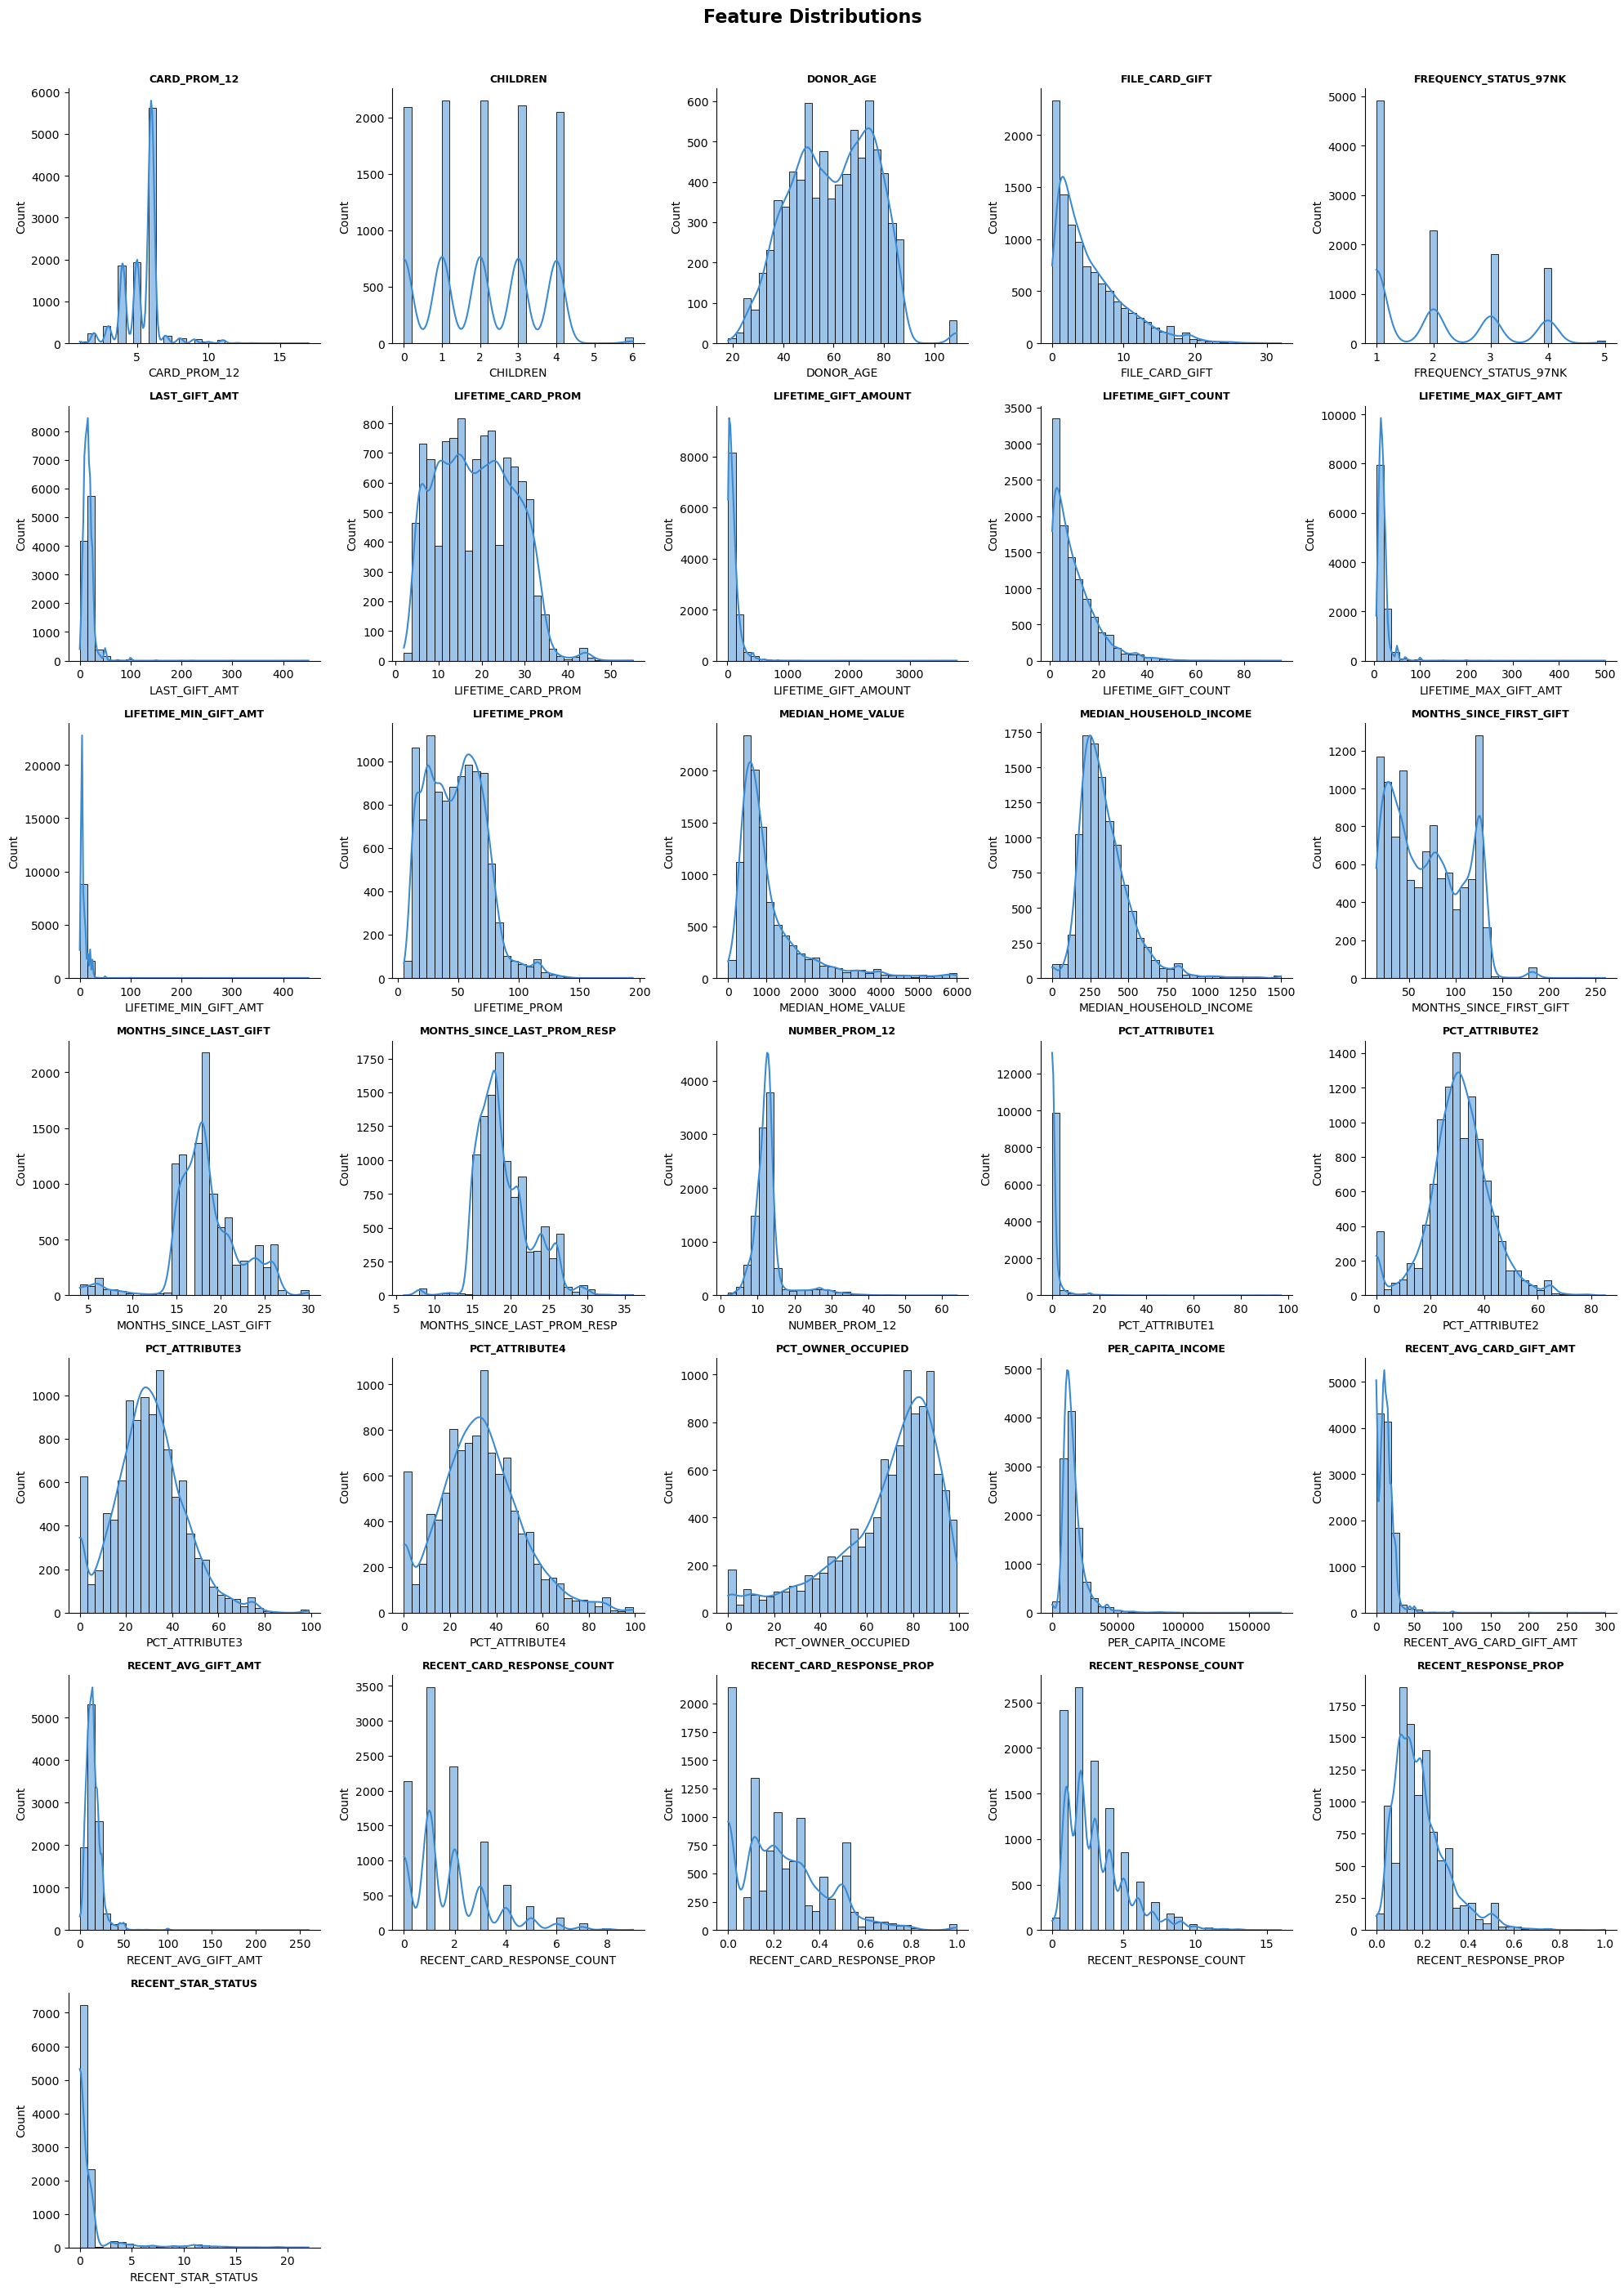

In [32]:
plot_cols = outlier_cols

n_cols = 5
n_rows = -(-len(plot_cols) // n_cols)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(20, n_rows * 4))
axes = axes.flatten()

for i, col in enumerate(plot_cols):
    sns.histplot(X_train[col].dropna(), bins=30, ax=axes[i], kde=True, color='#3B8BD4')
    axes[i].set_title(col, fontweight='bold', fontsize=9)
    axes[i].spines[['top', 'right']].set_visible(False)

for j in range(i+1, len(axes)):
    axes[j].set_visible(False)

plt.suptitle('Feature Distributions', fontsize=16, fontweight='bold', y=1.00)
plt.tight_layout(rect=[0, 0, 1, 0.99])
plt.show()

<h4><b>4.1.2 Log Transformation</b></h4>

A logarithmic transformation was applied to the most heavily right-skewed numerical variables, with the goal of compressing extreme values and bringing their distributions closer to symmetry. 

The `log1p` function (equivalent to log(1 + x)) was used instead of the standard logarithm, as it is numerically stable for zero values and avoids errors that would arise from log(0). This transformation was applied to a candidate set of features identified as right-skewed during the exploratory analysis and the outlier detection step.

To ensure that the log transformation was actually beneficial, a verification step was conducted. The number of outliers per feature was recomputed after the transformation and compared against the original counts. Features whose outlier counts decreased were retained in their log-transformed form, while those whose counts remained unchanged or worsened were reverted to their original values.

In [33]:
log_cols_candidates = ["LAST_GIFT_AMT", "LIFETIME_GIFT_AMOUNT", "LIFETIME_MAX_GIFT_AMT",
                      "LIFETIME_MIN_GIFT_AMT", "MEDIAN_HOME_VALUE", "MEDIAN_HOUSEHOLD_INCOME",
                      "PER_CAPITA_INCOME", "RECENT_AVG_CARD_GIFT_AMT", "RECENT_AVG_GIFT_AMT",
                      "LIFETIME_GIFT_COUNT", "RECENT_STAR_STATUS", "FILE_CARD_GIFT"]

def apply_log(df, cols):
    for col in cols:
        df[col] = np.log1p(df[col])
    return df

X_train_before_log = X_train.copy()
X_val_before_log   = X_val.copy()

In [34]:
X_train = apply_log(X_train, log_cols_candidates)
X_val   = apply_log(X_val,   log_cols_candidates)

In [35]:
outliers_before = count_outliers(X_train_before_log, outlier_cols)['Count']
outliers_after  = count_outliers(X_train,            outlier_cols)['Count']

comparison = pd.DataFrame({"Before Log": outliers_before, "After Log": outliers_after})
comparison["Difference"] = comparison["After Log"] - comparison["Before Log"]
comparison["Result"] = comparison["Difference"].apply(
    lambda x: "IMPROVED" if x < 0 else ("WORSE" if x > 0 else "=")
)
comparison[comparison["Difference"] != 0].sort_values("Difference")

,Before Log,After Log,Difference,Result
MEDIAN_HOME_VALUE,993,312,-681,IMPROVED
LIFETIME_GIFT_AMOUNT,574,25,-549,IMPROVED
LIFETIME_MIN_GIFT_AMT,480,46,-434,IMPROVED
LIFETIME_GIFT_COUNT,421,5,-416,IMPROVED
RECENT_STAR_STATUS,1011,645,-366,IMPROVED
FILE_CARD_GIFT,299,0,-299,IMPROVED
PER_CAPITA_INCOME,642,426,-216,IMPROVED
MEDIAN_HOUSEHOLD_INCOME,379,262,-117,IMPROVED
RECENT_AVG_GIFT_AMT,324,218,-106,IMPROVED
LAST_GIFT_AMT,326,259,-67,IMPROVED


In [36]:
no_benefit = comparison[
    (comparison["Result"].isin(["WORSE", "="])) &
    (comparison.index.isin(log_cols_candidates))
].index.tolist()
print(f"Columns reverted to original (no log benefit): {no_benefit}")

for col in no_benefit:
    X_train[col] = X_train_before_log[col]
    X_val[col]   = X_val_before_log[col]

# Final list of columns that actually keep the log transform
log_cols = [c for c in log_cols_candidates if c not in no_benefit]
print(f"Columns kept with log transform: {log_cols}")

Columns reverted to original (no log benefit): ['LIFETIME_MAX_GIFT_AMT', 'RECENT_AVG_CARD_GIFT_AMT']
Columns kept with log transform: ['LAST_GIFT_AMT', 'LIFETIME_GIFT_AMOUNT', 'LIFETIME_MIN_GIFT_AMT', 'MEDIAN_HOME_VALUE', 'MEDIAN_HOUSEHOLD_INCOME', 'PER_CAPITA_INCOME', 'RECENT_AVG_GIFT_AMT', 'LIFETIME_GIFT_COUNT', 'RECENT_STAR_STATUS', 'FILE_CARD_GIFT']


<h4><b>4.1.3 Outlier Treatment</b></h4>

Following the log transformation, winsorization was applied to address the outliers that still remained. Instead of removing observations, winsorization caps extreme values at predefined lower and upper quantiles, reducing the influence of outliers while preserving all observations in the dataset. 

The lower and upper quantiles were set at the 1st and 99th percentiles respectively, a conservative choice that affects only the most extreme 2% of values in each feature. 

We also decide to only apply winsorization in variables presenting more than 100 outliers after the log transformation.

In [37]:
def winsorize(reference_df, apply_to_df, cols, lower=0.01, upper=0.99):
    for col in cols:
        lower_bound = reference_df[col].quantile(lower)
        upper_bound = reference_df[col].quantile(upper)
        apply_to_df[col] = apply_to_df[col].clip(lower_bound, upper_bound)
    return apply_to_df

# Compute the final set of columns to winsorise: those with > 100 outliers after log
outliers_post_log = count_outliers(X_train, outlier_cols)['Count']
winsorize_cols = [c for c in outlier_cols if outliers_post_log[c] > 100]
print(f"Columns to winsorise: {winsorize_cols}")

Columns to winsorise: ['CARD_PROM_12', 'LAST_GIFT_AMT', 'LIFETIME_MAX_GIFT_AMT', 'MEDIAN_HOME_VALUE', 'MEDIAN_HOUSEHOLD_INCOME', 'MONTHS_SINCE_LAST_GIFT', 'MONTHS_SINCE_LAST_PROM_RESP', 'NUMBER_PROM_12', 'PCT_ATTRIBUTE1', 'PCT_ATTRIBUTE2', 'PCT_ATTRIBUTE3', 'PCT_ATTRIBUTE4', 'PCT_OWNER_OCCUPIED', 'PER_CAPITA_INCOME', 'RECENT_AVG_CARD_GIFT_AMT', 'RECENT_AVG_GIFT_AMT', 'RECENT_CARD_RESPONSE_COUNT', 'RECENT_CARD_RESPONSE_PROP', 'RECENT_RESPONSE_COUNT', 'RECENT_RESPONSE_PROP', 'RECENT_STAR_STATUS']


In [38]:
X_train = winsorize(X_train, X_train, winsorize_cols)
X_val   = winsorize(X_train, X_val,   winsorize_cols)

<h2 id = "p4-2" style="color:#006699;">4.2 Missing Values</h2> <a class="anchor" id="p3-1"></a>

Following the correction of inconsistencies and the treatment of outliers, the next preprocessing step addressed was the missing values present in the dataset. 

A function was implemented to summarise, for each feature, both the absolute number and the percentage of missing observations relative to the total number of training rows. This overview allows the missingness patterns to be examined feature by feature and supports the selection of the most appropriate imputation strategy for each case. 

In [39]:
def count_missing(df):
    counts = df.isnull().sum()
    percentages = (counts / len(df) * 100).round(2)
    
    result = pd.DataFrame({
        'Count': counts,
        'Percentage (%)': percentages
    })
    return result.sort_values('Count', ascending=False)

count_missing(X_train)

,Count,Percentage (%)
WEALTH_RATING,5102,47.03
DONOR_AGE,2981,27.48
INCOME_GROUP,2745,25.30
DONOR_GENDER,784,7.23
SES,470,4.33
URBANICITY,453,4.18
MONTHS_SINCE_LAST_PROM_RESP,369,3.40
LIFETIME_MIN_GIFT_AMT,342,3.15
PEP_STAR,321,2.96
LAST_GIFT_AMT,314,2.89


After analysing the output above, three variables stand out with substantially higher proportions of missing observations, `WEALTH_RATING` (47.0%), `DONOR_AGE` (27.5%), and `INCOME_GROUP` (25.3%). 

The vast majority of the remaining variables share a similar pattern, with missing percentages clustered between 2% and 3.5%. 

Based on these observations, different approaches will be applicated to different features.

<h4><b>4.2.1 Missing Values Treatment</b></h4>

<b>WEALTH_RATING</b>

The variable `WEALTH_RATING` was removed from both training and validation datasets due to its extremly high percentage of missing (approximately 47%), which could negatively impact the reliability of the imputations and the modeling process.

In [40]:
X_train = X_train.drop(columns='WEALTH_RATING')
X_val = X_val.drop(columns='WEALTH_RATING')

<b>HOME_OWNER</b>

For the feature `HOME_OWNER`, missing observations were replaced with the category "U" meaning unknown, preserving the categorical nature of the variable while explicitly representing undefined information.

In [41]:
X_train['HOME_OWNER'] = X_train['HOME_OWNER'].fillna('U')
X_val['HOME_OWNER'] = X_val['HOME_OWNER'].fillna('U')

<b> Other imputation strategies for other columns </b>

Different imputation techniques were then applied depending on the type and percentage of missing values:
- Variables with more than 20% of missing values, such as `DONOR_AGE` and `INCOME_GROUP`, were imputed using the K-Nearest Neighbors (KNN) imputation method. This approach estimated missing values based on the similarity between observations and preserves relationships between variables more effectively than simple statistical imputations.
- Categorical variables such as `DONOR_GENDER`, `SES`, and `URBANICITY` were imputed using the mode, since these variables contain a relatively low proportion of missing observations.
- The remaining numerical variables with low percentages of missing values were imputed using the mean value calculated exclusively from the training set.

In [42]:
def impute_missing(reference_df, apply_to_df, knn_cols, mode_cols, exclude_cols, knn_neighbors=5):
    """
    Imputes missing values using different strategies per column group:
    - KNN imputation for high-missingness columns
    - Mode imputation for binary/categorical columns
    - Mean imputation for remaining numeric columns
    """
    
    # KNN imputation
    knn_imputer = KNNImputer(n_neighbors=knn_neighbors, weights='distance')
    knn_imputer.fit(reference_df[knn_cols])
    apply_to_df[knn_cols] = knn_imputer.transform(apply_to_df[knn_cols])
    
    # Mode imputation
    mode_imputer = SimpleImputer(strategy='most_frequent')
    mode_imputer.fit(reference_df[mode_cols])
    apply_to_df[mode_cols] = mode_imputer.transform(apply_to_df[mode_cols])
    
    # Mean imputation for remaining numeric columns
    remaining_cols = [col for col in reference_df.select_dtypes(include='number').columns
                      if col not in knn_cols + mode_cols + exclude_cols]
    mean_imputer = SimpleImputer(strategy='mean')
    mean_imputer.fit(reference_df[remaining_cols])
    apply_to_df[remaining_cols] = mean_imputer.transform(apply_to_df[remaining_cols])
    
    return apply_to_df

In [43]:
# Define column groups
knn_cols = ['DONOR_AGE', 'INCOME_GROUP']
mode_cols = ['DONOR_GENDER', 'SES', 'URBANICITY']
exclude_cols = ['RECENCY_STATUS_96NK', 'PEP_STAR']

In [44]:
# Apply imputation
X_train = impute_missing(X_train, X_train, knn_cols, mode_cols, exclude_cols)
X_val   = impute_missing(X_train, X_val,   knn_cols, mode_cols, exclude_cols)

<b>PEP_STAR and RECENCY_STATUS_96NK</b>

Additional rule-based imputation were also performed using logical relationships between variables:
- Missing values in `PEP_STAR` were inferred using `RECENCY_STATUS_96NK`. Donors classified with statues "S" were assigned `PEP_STAR`= 1, while others were assigned 0.
- Missing values in `RECENCY_STATUS_96NK` were inferred using donor activity variables such as `PEP_STAR`, `MONTHS_SINCE_LAST_GIFT`, `MONTHS_SINCE_FIRST_GIFT`, and `LIFETIME_GIFT_COUNT`. Logical rules were applied to classifiy donors into categories such as active(A), star(S), inactive(E), lapsing(L), first-time(F), and new(N).

In [45]:
def infer_pep_star(df):
    """
    Infer PEP_STAR from RECENCY_STATUS_96NK:
    if status == "S" (star), PEP_STAR = 1, else 0.
    """
    df.loc[(df["PEP_STAR"].isna()) & (df["RECENCY_STATUS_96NK"] == "S"), "PEP_STAR"] = 1
    df.loc[(df["PEP_STAR"].isna()) & (df["RECENCY_STATUS_96NK"] != "S"), "PEP_STAR"] = 0
    return df

In [46]:
def infer_recency_status(df):
    """
    Infer RECENCY_STATUS_96NK from donation history:
    - S (star):  PEP_STAR == 1
    - E (inactive): last gift >= 25 months ago
    - L (lapsing):  last gift between 13 and 24 months ago
    - F (first):    first gift <= 6 months ago AND only 1 lifetime gift
    - N (new):      first gift <= 12 months ago AND not F
    - A (active):   last gift <= 12 months ago AND first gift > 12 months ago
    """
    mask = df["RECENCY_STATUS_96NK"].isna()

    df.loc[mask & (df["PEP_STAR"] == 1), "RECENCY_STATUS_96NK"] = "S"
    df.loc[mask & (df["MONTHS_SINCE_LAST_GIFT"] >= 25), "RECENCY_STATUS_96NK"] = "E"
    df.loc[mask & (df["MONTHS_SINCE_LAST_GIFT"] >= 13) & (df["MONTHS_SINCE_LAST_GIFT"] <= 24),
           "RECENCY_STATUS_96NK"] = "L"
    df.loc[mask & (df["MONTHS_SINCE_FIRST_GIFT"] <= 6) & (df["LIFETIME_GIFT_COUNT"] == 1),
           "RECENCY_STATUS_96NK"] = "F"
    df.loc[mask & (df["MONTHS_SINCE_FIRST_GIFT"] <= 12) & (df["RECENCY_STATUS_96NK"].isna()),
           "RECENCY_STATUS_96NK"] = "N"
    df.loc[mask & (df["MONTHS_SINCE_LAST_GIFT"] <= 12) & (df["MONTHS_SINCE_FIRST_GIFT"] > 12),
           "RECENCY_STATUS_96NK"] = "A"

    return df

In [47]:
X_train = infer_pep_star(X_train)
X_val = infer_pep_star(X_val)

In [48]:
X_train = infer_recency_status(X_train)
X_val = infer_recency_status(X_val)

<h2 id = "p4-3" style="color:#006699;">4.3 Encoding</h2>

Since machine learning algorithms require numerical inputs, the categorical variables present in the dataset were transformed using different encoding techniques according to the nature of each feature.

For this reason, three distinct encoding strategies were adopted in this project, each applied to a specific type of categorical variable. Variables with only two possible values were converted through a simple binary mapping, while those whose categories carry a natural ordering were transformed using ordinal encoding. Finally, nominal variables without any inherent hierarchy were encoded through a one-hot enconding, where each category becomes an independent binary indicator.

<h3 style="color:#006699;">4.3.1 Binary Encoding</h3> <a class="anchor" id="p3-1"></a>

<b> home_owner and donor_gender </b> 

Starting with the binary encoding, this approach was applied to the variables `HOME_OWNER` and `DONOR_GENDER`, since both variables contain only two meaningful categories. The categories were converted into binary numerical values to simplify their representation while preserving their original meaning.
- `HOME_OWNER`: 
    - H - 1
    - U - 0
- `DONOR_GENDER`: 
    - F - 1 
    - H - 0

In [49]:
binary_maps = {
    "HOME_OWNER":   {"H": 1, "U": 0},
    "DONOR_GENDER": {"F": 1, "M": 0}
}

def binary_encoding(df, mappings):
    for col, mapping in mappings.items():
        df[col] = df[col].map(mapping)
    return df

In [50]:
X_train = binary_encoding(X_train, binary_maps)
X_val   = binary_encoding(X_val,   binary_maps)

<h3 style="color:#006699;">4.3.2 Ordinal Enconding</h3> <a class="anchor" id="p3-1"></a>

<b> SES </b>

Ordinal encoding was applied to the variable `SES` because its categories possess an inherent order representing socioeconomic status levels. The categories were encoded according to their natural ranking:
- 1 < 2 < 3 < 4

The OrdinalEncoder from scikit-learn was used to preserve this ordinal relationship between categories. Special attention was given to missing and unknown values by configuring the encoder to handle unseen or undefined categories without generating errors during transformation.

In [51]:
def ordinal_encoding(reference_df, apply_to_df, col, categories):
    encoder = OrdinalEncoder(categories=[categories], 
                             handle_unknown='use_encoded_value', 
                             unknown_value=np.nan)
    reference_df[col] = encoder.fit_transform(reference_df[[col]])
    apply_to_df[col] = encoder.transform(apply_to_df[[col]])
    return reference_df, apply_to_df


In [52]:
X_train, X_val = ordinal_encoding(X_train, X_val, 'SES', ['1', '2', '3', '4'])

<h3 style="color:#006699;">4.3.3 One-Hot Encoding</h3> <a class="anchor" id="p3-1"></a>

<b> URBANICITY and RECENCY_STATUS_96NK </b>

One-Hot Encoding was applied to the variables `URBANICITY` and `RECENCY_STATUS_96NK` since these variables represent nominal categories without a natural order.

This approach creates a new binary column for each category, allowing the models to interpret each category independently without assuming any ordinal relationship between them.

To avoid inconsistencies between datasets, the encoder was fitted exclusively on the training set and then applied to the validation set.

In [53]:
columns_onehot = ["URBANICITY", "RECENCY_STATUS_96NK"]

def onehot_encoding(reference_df, apply_to_df, cols):
    encoder = OneHotEncoder(sparse_output=False, handle_unknown="ignore")
    encoded_ref = encoder.fit_transform(reference_df[cols])
    encoded_app = encoder.transform(apply_to_df[cols])

    feature_names = encoder.get_feature_names_out(cols)

    reference_df = reference_df.drop(columns=cols)
    apply_to_df  = apply_to_df.drop(columns=cols)

    reference_df[feature_names] = encoded_ref
    apply_to_df[feature_names]  = encoded_app

    return reference_df, apply_to_df

In [54]:
X_train, X_val = onehot_encoding(X_train, X_val, columns_onehot)

<h2 id = "p4-4" style="color:#006699;">4.4 Feature Engineering</h2>

Feature engineering techniques were applied to create new variables capable of providing additional and better information to the machine learning models.

<b>Average Lifetime Donation Amount</b>

It was created a new variable, `AVG_LIFETIME_GIFT`, which represents the average donation amount per donor throughout their donation history. This feature was calculated by dividing the total lifetime donation amount (`LIFETIME_GIFT_AMOUNT`) by the total number of lifetime donation (`LIFETIME_GIFT_COUNT`).

<b> DONATION_TENURE_MONTHS </b>

It was created a new variable, `DONATION_TENURE_MONTHS`, which represents how long a donor has been actively contributing to the organization. This feature was calculated by subtracting the months since the last donation (`MONTHS_SINCE_LAST_GIFT`) from the months since the first donation (`MONTHS_SINCE_FIRST_GIFT`).

<b> GIFT_FREQUENCY </b>

It was created a new variable, `GIFT_FREQUENCY`, which represents how often a donor contributes over time. This feature was calculated by dividing the total number of lifetime donations (`LIFETIME_GIFT_COUNT`) by the months since the first donation (`MONTHS_SINCE_FIRST_GIFT`).

<b> LAST_VS_AVG_RATIO </b>

It was created a new variable, `LAST_VS_AVG_RATIO`, which compares the most recent donation amount to the donor's historical average. This feature was calculated by dividing the last gift amount (`LAST_GIFT_AMT`) by the average lifetime gift (`AVG_LIFETIME_GIFT`).

<b> GIFT_RANGE </b>

It was created a new variable, `GIFT_RANGE`, which represents the variability of a donor's contributions. This feature was calculated by subtracting the minimum lifetime donation amount (`LIFETIME_MIN_GIFT_AMT`) from the maximum lifetime donation amount (`LIFETIME_MAX_GIFT_AMT`).


In [55]:
def create_features(df):    
    # Average gift amount per donation over the donor's lifetime
    df['AVG_LIFETIME_GIFT'] = df['LIFETIME_GIFT_AMOUNT'] / df['LIFETIME_GIFT_COUNT'].replace(0, 1)
    
    # Donor activity tenure — how prolonged the relationship is
    df['DONATION_TENURE_MONTHS'] = df['MONTHS_SINCE_FIRST_GIFT'] - df['MONTHS_SINCE_LAST_GIFT']
    
    # Average donation frequency (gifts per month since becoming a donor)
    df['GIFT_FREQUENCY'] = df['LIFETIME_GIFT_COUNT'] / df['MONTHS_SINCE_FIRST_GIFT'].replace(0, 1)
    
    # Last gift compared to historical average (>1 = trending up, <1 = trending down)
    df['LAST_VS_AVG_RATIO'] = df['LAST_GIFT_AMT'] / df['AVG_LIFETIME_GIFT'].replace(0, 1)
    
    # Donation range (variability between max and min gift)
    df['GIFT_RANGE'] = df['LIFETIME_MAX_GIFT_AMT'] - df['LIFETIME_MIN_GIFT_AMT']
    
    return df

In [56]:
X_train = create_features(X_train)
X_val = create_features(X_val)

<h2 id = "p4-5" style="color:#006699;">4.5 Scaling</h2>

Scaling was implemented on the numerical variables to reduce the influence of diffence variable magnitudes and improve the effectiveness of machine learning algorithms that are sensitive to feature scales.

In this project, the <b>RobustScaler</b> method was chosen since several numerical variables continued to show skewed distributions and persistent extreme values, even after the outlier treatment phase. RobustScaler, in contrast to typical normalization techniques, employs the median and interquartile range (IQR), which enhances its resilience to outliers.

The scaling procedure was applied exclusively on continuous numerical variables. Binary variables like `PEP_STAR`, `HOME_OWNER`, and `DONOR_GENDER`, along with the one-hot encoded variables originating from `URBANICITY` and `RECENCY_STATUS_96NK`, were left out of scaling to maintain their categorical meaning.

To avoid data leakage, the scaler was only adjusted on the training set and then used on both the training and validation datasets.


In [57]:
def scale_features(reference_df, apply_to_df):
    binary_cols = ["PEP_STAR", "HOME_OWNER", "DONOR_GENDER"]
    onehot_cols = [c for c in reference_df.columns
                   if c.startswith("URBANICITY_") or c.startswith("RECENCY_STATUS_96NK_")]
    exclude = binary_cols + onehot_cols

    scale_cols = [c for c in reference_df.select_dtypes(include="number").columns if c not in exclude]

    scaler = RobustScaler()
    scaler.fit(reference_df[scale_cols])
    apply_to_df[scale_cols] = scaler.transform(apply_to_df[scale_cols])
    return apply_to_df

X_train_pre_scale = X_train.copy()

In [58]:
X_train = scale_features(X_train_pre_scale, X_train)
X_val   = scale_features(X_train_pre_scale, X_val)

<h2 id="p4-6" style="color:#006699;">4.6 Feature Selection</h2>

In data preprocessing, feature selection is considered a very important step, as it identifies the most relevant features for model building. Several techniques were used to lower dimensionality, remove redundant data, and improve the overall performance and interpretability of the machine learning models. Given that the dataset includes a substantial number of variables, multiple complementary feature selection methods were evaluated and contrasted prior to determining the final set of features.

Different approaches were employed to assess the relevance of the variables, such as correlation analysis and filter techniques.


<h3 style="color:#006699;">4.6.1 Correlation Analysis - Heatmap</h3> <a class="anchor" id="p3-1"></a>

Starting with correlation heatmaps, this maps were generated to examine the relationships between numerical variables and detect possible correlations among features. Pearson's correlation coefficient was chosen to measure the linear relationships between numerical variables. Although Spearman's rank-based correlation is more robust to skewness and outliers, those conditions were already mitigated in the previous preprocessing steps through log transformation and winsorization. To improve interpretability, the variables were categorized into two groups:
- demographic and economic variables;
- donation behavior and donor activities variables.

The heatmaps revealed several strong positive correlations, especially between donation-related variables. For instance, `LIFETIME_PROM` and `LIFETIME_CARD_PROM` exhibited a significant correlation, suggesting that donors who received a greater number of lifetime promotions were likely to receive more card promotions as well. Likewise, `LIFETIME_GIFT_COUNT` showed a strong correlation with `FILE_CARD_GIFT`, indicating that donors who have made more lifetime donations tend to participate more often in card gift campaigns.

Strong correlations were also noted among variables associated with recent donor activities, including `RECENT_RESPONSE_COUNT`, `RECENT_CARD_RESPONSE_COUNT`, and their respective response ratios. These correlations suggest that donor engagement metrics reflect similar behavioral trends.

The engineered features introduced during feature engineering also display strong correlations with the original variables from which they were derived. For example, `DONATION_TENURE_MONTHS` is almost perfectly correlated with `MONTHS_SINCE_FIRST_GIFT`, and `GIFT_RANGE` is fully correlated with `LIFETIME_MAX_GIFT_AMT`, since both are computed from them. 

In the demographic and socioeconomic category, moderate to strong positive correlations were found between `MEDIAN_HOME_VALUE`, `MEDIAN_HOUSEHOLD_INCOME`, and `PER_CAPITA_INCOME`, which is expected as these variables represent related socioeconomic factors. Negative correlations were also observed between `SES` and income-related factors, indicating the ordinal structure of the socioeconomic status variable.

This analysis was crucial to identify redundant data and support later feature selection choices, decreasing multicollinearity and enhancing model interpretability.

In [59]:
def heatmap(df, title='Features Correlation Heatmap'):
    
    corr = df.corr(method='pearson', numeric_only=True)
    
    fig = go.Figure(go.Heatmap(
        z=corr.values,
        x=corr.columns,
        y=corr.columns,
        colorscale='RdBu_r',
        zmin=-1,
        zmax=1
    ))
    
    fig.update_traces(text=corr.values.round(2), texttemplate='%{text}', textfont_size=10)
    
    fig.update_layout(
        title=title,
        title_x=0.5,
        width=1200,
        height=1000
    )
    
    fig.show()

In [60]:
donation_cols = ['LAST_GIFT_AMT', 'LIFETIME_GIFT_AMOUNT', 'LIFETIME_GIFT_COUNT', 
                 'LIFETIME_MAX_GIFT_AMT', 'LIFETIME_MIN_GIFT_AMT', 'FILE_CARD_GIFT',
                 'RECENT_AVG_GIFT_AMT', 'RECENT_AVG_CARD_GIFT_AMT', 'RECENT_RESPONSE_COUNT',
                 'RECENT_CARD_RESPONSE_COUNT', 'RECENT_RESPONSE_PROP', 'RECENT_CARD_RESPONSE_PROP',
                 'FREQUENCY_STATUS_97NK', 'PEP_STAR', 'RECENT_STAR_STATUS', 'MONTHS_SINCE_LAST_GIFT',
                 'MONTHS_SINCE_FIRST_GIFT', 'MONTHS_SINCE_LAST_PROM_RESP', 'LIFETIME_PROM',
                 'LIFETIME_CARD_PROM', 'CARD_PROM_12', 'NUMBER_PROM_12', 'AVG_LIFETIME_GIFT', 
                 'DONATION_TENURE_MONTHS', 'GIFT_FREQUENCY','LAST_VS_AVG_RATIO', 'GIFT_RANGE']

demographic_cols = ['DONOR_AGE', 'DONOR_GENDER', 'HOME_OWNER', 'CHILDREN', 'INCOME_GROUP',
                    'SES', 'MEDIAN_HOME_VALUE', 'MEDIAN_HOUSEHOLD_INCOME', 'PER_CAPITA_INCOME',
                    'PCT_OWNER_OCCUPIED', 'PCT_ATTRIBUTE1', 'PCT_ATTRIBUTE2', 'PCT_ATTRIBUTE3', 
                    'PCT_ATTRIBUTE4']

# Keep only columns that actually exist
donation_cols    = [c for c in donation_cols if c in X_train.columns]
demographic_cols = [c for c in demographic_cols if c in X_train.columns]

heatmap(X_train[donation_cols],    title='Donation Behaviour - Correlation Heatmap')
heatmap(X_train[demographic_cols], title='Demographic & Socioeconomic - Correlation Heatmap')

<h3 style="color:#006699;">4.6.2 Filter Methods</h3> <a class="anchor" id="p3-1"></a>

Filter methods are techniques for feature selection that evaluate the relevance of variables without considering the machine learning model. These approaches depend on the statistical characteristics of the data to detect irrelevant, redundant, or low-informative features prior to the modeling phase.

A key benefit of filter methods is their computational efficiency, as they don’t need to train the model multiple times. They also aid in minimizing dimensionality, improve interpretability, decrease noise, and possibly improving model effectiveness.

In this project, three distinct filtering methods were utilized:
- <b>Analysis of constant and quasi-constant features</b>, used to detect variables exhibiting minimal variance and restricted information;
- <b>Correlation among features</b>, used to identify highly correlated variables that could lead to redundancy and multicollinearity within the dataset;
- <b>Correlation with the target variable</b>, used to detect variables that exhibit weak associations with the target variable (`TARGET_B`) and may have low predictive importance.

These techniques offered an initial statistical evaluation of feature significance and aided in the following feature selection choices.


<h4> <b>Constant and Quasi-Constant Features</b> </h4>

The VarianceThreshold method was used to identify constant or quasi-constant variables. No constant or near-constant were detected in the dataset.

In [61]:
def identify_constant_features(df, threshold=0.01):
    selector = VarianceThreshold(threshold=threshold)
    selector.fit(df.select_dtypes(include='number'))
    
    constant_features = df.select_dtypes(include='number').columns[~selector.get_support()].tolist()
    print(f'Constant/quasi-constant features ({len(constant_features)}): {constant_features}')
    return constant_features

In [62]:
constant_features = identify_constant_features(X_train)

Constant/quasi-constant features (0): []


<h4> <b>Correlation betweeen features</b> </h4>

Pearson correlation analysis was employed to find highly correlated variables (correlation exceeding 0.8). While these relationships could already be visually observed in the correlation heatmap above, listing them explicitly here makes the redundant pairs easier to identify and interpret.

High correlations were found among variables like:
- `LIFETIME_GIFT_AMOUNT` and `LIFETIME_CARD_PROM`;
- `LIFETIME_GIFT_COUNT` and `FILE_CARD_GIFT`, `LIFETIME_CARD_PROM`, `LIFETIME_GIFT_AMOUNT`;
- `LIFETIME_PROM` and `LIFETIME_CARD_PROM`, `LIFETIME_GIFT_AMOUNT`, `LIFETIME_GIFT_COUNT`;
- `MONTHS_SINCE_FIRST_GIFT` and `LIFETIME_CARD_PROM`, `LIFETIME_PROM`;
- `AVG_LIFETIME_GIFT` and `LIFETIME_GIFT_COUNT`;
- `DONATION_TENURE_MONTHS` and `LIFETIME_CARD_PROM`, `LIFETIME_PROM`, `MONTHS_SINCE_FIRST_GIFT`;
- `GIFT_RANGE` and `LIFETIME_MAX_GIFT_AMT`.

These relationships suggest the existence of overlapping information that may harm model interpretability and heighten multicollinearity.


In [63]:
def identify_correlated_features(df, threshold=0.8):

    corr_matrix = df.select_dtypes(include='number').corr().abs()
    
    # Get upper triangle of correlation matrix
    upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
    
    correlated_features = [col for col in upper.columns if any(upper[col] > threshold)]
    
    print(f'Correlated features ({len(correlated_features)}): {correlated_features}')
    
    # Show the pairs
    for col in correlated_features:
        correlated_with = upper.index[upper[col] > threshold].tolist()
        print(f'  {col} correlated with: {correlated_with}')
    
    return correlated_features

In [64]:
correlated_features = identify_correlated_features(X_train)

Correlated features (7): ['LIFETIME_GIFT_AMOUNT', 'LIFETIME_GIFT_COUNT', 'LIFETIME_PROM', 'MONTHS_SINCE_FIRST_GIFT', 'AVG_LIFETIME_GIFT', 'DONATION_TENURE_MONTHS', 'GIFT_RANGE']
  LIFETIME_GIFT_AMOUNT correlated with: ['LIFETIME_CARD_PROM']
  LIFETIME_GIFT_COUNT correlated with: ['FILE_CARD_GIFT', 'LIFETIME_CARD_PROM', 'LIFETIME_GIFT_AMOUNT']
  LIFETIME_PROM correlated with: ['LIFETIME_CARD_PROM', 'LIFETIME_GIFT_AMOUNT', 'LIFETIME_GIFT_COUNT']
  MONTHS_SINCE_FIRST_GIFT correlated with: ['LIFETIME_CARD_PROM', 'LIFETIME_PROM']
  AVG_LIFETIME_GIFT correlated with: ['LIFETIME_GIFT_COUNT']
  DONATION_TENURE_MONTHS correlated with: ['LIFETIME_CARD_PROM', 'LIFETIME_PROM', 'MONTHS_SINCE_FIRST_GIFT']
  GIFT_RANGE correlated with: ['LIFETIME_MAX_GIFT_AMT']


<h4> <b>Correlation with the target</b> </h4>

The relationship between numerical variables and the target variable (`TARGET_B`) was also analyzed. Attributes with low correlation values were identified as possibly being less useful for forecasting donor behavior.

Variables like `DONOR_GENDER`, `CHILDREN` and various socioeconomic percentage factors showed especially weak correlations with the target variable.

In [65]:
def identify_low_correlation_features(df, target, threshold=0.05):
    corr_target = df.select_dtypes(include='number').corrwith(target).abs().sort_values(ascending=False)
    
    low_corr_features = corr_target[corr_target < threshold].index.tolist()
    
    print(f'Features with low correlation with target ({len(low_corr_features)}):')
    print(corr_target[corr_target < threshold].round(3))
    
    return low_corr_features

In [66]:
low_corr_features = identify_low_correlation_features(X_train, y_train)

Features with low correlation with target (29):
MEDIAN_HOME_VALUE           0.049
NUMBER_PROM_12              0.045
SES                         0.043
PER_CAPITA_INCOME           0.042
CARD_PROM_12                0.041
RECENCY_STATUS_96NK_A       0.036
URBANICITY_R                0.033
MEDIAN_HOUSEHOLD_INCOME     0.033
RECENT_STAR_STATUS          0.033
LAST_VS_AVG_RATIO           0.032
INCOME_GROUP                0.027
URBANICITY_S                0.024
DONOR_AGE                   0.020
RECENCY_STATUS_96NK_L       0.019
HOME_OWNER                  0.019
RECENCY_STATUS_96NK_E       0.018
PCT_ATTRIBUTE4              0.017
RECENCY_STATUS_96NK_N       0.017
GIFT_FREQUENCY              0.015
URBANICITY_T                0.014
PCT_ATTRIBUTE2              0.010
URBANICITY_C                0.008
RECENT_AVG_CARD_GIFT_AMT    0.007
PCT_ATTRIBUTE3              0.007
PCT_ATTRIBUTE1              0.005
PCT_OWNER_OCCUPIED          0.003
CHILDREN                    0.003
DONOR_GENDER                0.002


<h3 style="color:#006699;">4.6.3 Comparison of Feature Selection Methods</h3> <a class="anchor" id="p3-1"></a>

The outcomes from the two correlation-based methods were combined to decide which variables should be eliminated from the final dataset.

For every pair of features identified as highly correlated, the one with the lower absolute correlation with the target variable (`TARGET_B`) was removed, retaining the feature expected to contribute more to the predictive task. Variables with very low correlation with the target were also flagged as candidates for elimination.

Additionally:
- Variables that were highly correlated (>0.8) were eliminated based on the one that had a lower correlation with the target variable (`TARGET_B`);
- Variables with absolute correlation below 0.02 with the target were also removed, as they provided very limited predictive signal.

By integrating all selection criteria, 23 variables were eliminated, leading to a final dataset with 29 features.

In [67]:
def select_features(X_train, X_val, target,
                    feature_corr_threshold=0.8,
                    target_corr_threshold=0.02):
    """
    Feature selection based on two complementary correlation criteria:
    1. Redundancy: for each pair of features with absolute Pearson correlation
       above feature_corr_threshold, the one with weaker absolute correlation
       with the target is removed.
    2. Low information: features with absolute correlation with the target
       below target_corr_threshold are removed.
    """
    # Compute correlation matrices
    corr_matrix = X_train.select_dtypes(include='number').corr().abs()
    corr_target = X_train.select_dtypes(include='number').corrwith(target).abs()
    upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
    
    # 1. Correlation between features (remove redundant)
    redundant_removed = set()
    for col in upper.columns:
        highly_correlated = upper.index[upper[col] > feature_corr_threshold].tolist()
        for feat in highly_correlated:
            if corr_target.get(col, 0) < corr_target.get(feat, 0):
                redundant_removed.add(col)
            else:
                redundant_removed.add(feat)
    
    print(f"--- Features removed due to redundancy (|r| > {feature_corr_threshold}) ---")
    print(f"({len(redundant_removed)}) {sorted(redundant_removed)}\n")
    
    # 2. Correlation with target (remove low-information features)
    low_target_corr = corr_target[corr_target < target_corr_threshold].index.tolist()
    low_target_corr = set(low_target_corr) - redundant_removed
    
    print(f"--- Features removed due to low correlation with target (|r| < {target_corr_threshold}) ---")
    print(f"({len(low_target_corr)}) {sorted(low_target_corr)}\n")
    
    # Combine all removed
    total_removed = redundant_removed | low_target_corr
    print(f"--- Total ---")
    print(f"Total features removed: {len(total_removed)}")
    print(f"Features kept:          {len(X_train.columns) - len(total_removed)}")
    
    selected = [c for c in X_train.columns if c not in total_removed]
    return X_train[selected], X_val[selected], list(total_removed)

In [68]:
X_train_final, X_val_final, removed_features = select_features(
    X_train, X_val, y_train,
    feature_corr_threshold=0.8,
    target_corr_threshold=0.02
)

print(f"\nFinal feature set ({len(X_train_final.columns)} features):")
print(list(X_train_final.columns))

--- Features removed due to redundancy (|r| > 0.8) ---
(7) ['AVG_LIFETIME_GIFT', 'GIFT_RANGE', 'LIFETIME_CARD_PROM', 'LIFETIME_GIFT_AMOUNT', 'LIFETIME_GIFT_COUNT', 'LIFETIME_PROM', 'MONTHS_SINCE_FIRST_GIFT']

--- Features removed due to low correlation with target (|r| < 0.02) ---
(16) ['CHILDREN', 'DONOR_GENDER', 'GIFT_FREQUENCY', 'HOME_OWNER', 'PCT_ATTRIBUTE1', 'PCT_ATTRIBUTE2', 'PCT_ATTRIBUTE3', 'PCT_ATTRIBUTE4', 'PCT_OWNER_OCCUPIED', 'RECENCY_STATUS_96NK_E', 'RECENCY_STATUS_96NK_L', 'RECENCY_STATUS_96NK_N', 'RECENT_AVG_CARD_GIFT_AMT', 'URBANICITY_C', 'URBANICITY_T', 'URBANICITY_U']

--- Total ---
Total features removed: 23
Features kept:          29

Final feature set (29 features):
['CARD_PROM_12', 'DONOR_AGE', 'FILE_CARD_GIFT', 'FREQUENCY_STATUS_97NK', 'INCOME_GROUP', 'LAST_GIFT_AMT', 'LIFETIME_MAX_GIFT_AMT', 'LIFETIME_MIN_GIFT_AMT', 'MEDIAN_HOME_VALUE', 'MEDIAN_HOUSEHOLD_INCOME', 'MONTHS_SINCE_LAST_GIFT', 'MONTHS_SINCE_LAST_PROM_RESP', 'NUMBER_PROM_12', 'PEP_STAR', 'PER_CAPITA_I

<h1 id = "p5" style="color:#006699;">5. Modelling</h1>

The modelling stage seeks to determine the best predictive model for the classification problem, with a primary focus on maximizing the F1-score due to class imbalance. Given that the business context emphasized accurately identifying positive cases while minimizing false alarms, the F1-score offers a balanced evaluation of both precision and recall.

A wide range of machine learning algorithms was assessed, including both linear and non-linear appraoches along with ensemble methods. All models were trained on the same preprocessed training dataset (`X_train_final`, `y_train`) and evaluated on a separated validation set (`X_val_final`, `y_val`) to guarantee a uniform and fair comparison.

To ensure robustness, each model was tested under multiple hyperparameter configurations. The objective was not only to identify the best-performing algorithm but also to assess how sensitive each model is to parameter tuning and whether more complex methods provide meaningful improvements over simpler baselines.

<h2 id = "p5-1" style="color:#006699;">5.1 Model Selection</h2>

In [69]:
def models_comparison(models_dict, X_train, y_train, X_val, y_val):
    results = []
    for name, model in models_dict.items():
        print(f'Running {name}...')
        model.fit(X_train, y_train)
        train_pred = model.predict(X_train)
        val_pred   = model.predict(X_val)
        results.append({
            'Model':      name,
            'Train F1':   round(f1_score(y_train, train_pred), 4),
            'Val F1':     round(f1_score(y_val,   val_pred),   4),
            'Difference': round(f1_score(y_train, train_pred) - f1_score(y_val, val_pred), 4)
        })
    return pd.DataFrame(results).sort_values(
        ['Val F1', 'Difference'], ascending=[False, True]
    ).reset_index(drop=True)

<h4> <b> Logistic Regression </b> </h4>

Logistic Regression served as a baseline linear classifier due to its interpretability and effectiveness in binary classification tasks, particularly in scenarios of class imbalance when used with `class_weight='balanced'`.

Multiple configurations were evaluated, including variations in regularisation strength (C) and penalty type (L1 vs L2).

The best-performing configuration was: **LR (balanced, C=0.1): Val F1 = 0.3979**

In general, all balanced Logistic Regression models performed very similarly, displaying validation F1-scores around 0.39 and 0.40.

The default model, without class balancing, performed significantly worse (Val F1 = 0.0285), confirming the strong impact of class imbalance handling.

**Conclusions:**
- Class balancing was the most important factor improving performance.
- Regularisation strength (C) had only marginal impact.
- L1 regularisation did not significantly outperform L2.
- The small train–validation gap (~0.015) suggests good generalisation and low overfitting.

In [70]:
logistic_regression = {
    'LR (default)':         LogisticRegression(max_iter=2000, random_state=42),
    'LR (balanced)':        LogisticRegression(class_weight='balanced', max_iter=2000, random_state=42),
    'LR (balanced, C=0.1)': LogisticRegression(class_weight='balanced', C=0.1, max_iter=2000, random_state=42),
    'LR (balanced, C=10)':  LogisticRegression(class_weight='balanced', C=10, max_iter=2000, random_state=42),
    'LR (balanced, L1)':    LogisticRegression(class_weight='balanced', penalty='l1', solver='liblinear', max_iter=2000, random_state=42),
}

results_lr = models_comparison(logistic_regression, X_train_final, y_train, X_val_final, y_val)
results_lr

Running LR (default)...
Running LR (balanced)...
Running LR (balanced, C=0.1)...
Running LR (balanced, C=10)...
Running LR (balanced, L1)...


,Model,Train F1,Val F1,Difference
0,"LR (balanced, C=0.1)",0.4132,0.3979,0.0153
1,"LR (balanced, L1)",0.4130,0.3973,0.0158
2,"LR (balanced, C=10)",0.4130,0.3962,0.0168
3,LR (balanced),0.4131,0.3962,0.0169
4,LR (default),0.0372,0.0285,0.0086


<h4> <b> Decision Tree </b> </h4>

Decision Trees were evaluated with different depth limitations and minimum sample criteria to manage overfitting.

Although not presented in detail, DT generally demonstrated moderate validation performance but were affected by depth, as deeper trees exhibited indications of overfitting.

**Conclusions:**
- Shallow trees underfit the data.
- Deeper trees improved training efficiency but reduced generalization.
- Even with balancing, individual trees struggled to outperform Logistic Regression significantly.

This suggests that a single tree is not sufficiently stable for this dataset and motivates the use of ensemble methods.

In [71]:
decision_tree = {
    'DT (default, no limit)':       DecisionTreeClassifier(class_weight='balanced', random_state=42),
    'DT (max_depth=3)':             DecisionTreeClassifier(class_weight='balanced', max_depth=3, random_state=42),
    'DT (max_depth=5)':             DecisionTreeClassifier(class_weight='balanced', max_depth=5, random_state=42),
    'DT (max_depth=10)':            DecisionTreeClassifier(class_weight='balanced', max_depth=10, random_state=42),
    'DT (max_depth=5, min_leaf=20)': DecisionTreeClassifier(class_weight='balanced', max_depth=5, min_samples_leaf=20, random_state=42),
}

results_dt = models_comparison(decision_tree, X_train_final, y_train, X_val_final, y_val)
results_dt

Running DT (default, no limit)...
Running DT (max_depth=3)...
Running DT (max_depth=5)...
Running DT (max_depth=10)...
Running DT (max_depth=5, min_leaf=20)...


,Model,Train F1,Val F1,Difference
0,"DT (max_depth=5, min_leaf=20)",0.4153,0.3816,0.0338
1,DT (max_depth=5),0.4186,0.3813,0.0373
2,DT (max_depth=3),0.4137,0.3788,0.0348
3,DT (max_depth=10),0.5476,0.3648,0.1828
4,"DT (default, no limit)",1.0000,0.2918,0.7082


<h4> <b> Random Forest </b> </h4>

Random Forest was evaluated as a more robust ensemble method that integrated several decision trees trained on bootstrapped samples and random feature selection. 

The best-performing configuration was: **RF (n=100, max_depth=5) → Val F1 = 0.3715**

**Conclusions:**
- Limiting tree depth improved generalization performance.
- Increasing the number of trees from 100 to 200 had little impact on performance.
- Deeper trees increased overfitting, as shown by the larger gap between training and validation F1-scores.
- The unconstrained Random Forest strongly overfitted the training data, achieving near-perfect training performance but poor validation results.

In [72]:
random_forest = {
    'RF (default, balanced)':             RandomForestClassifier(class_weight='balanced', n_estimators=100, random_state=42),
    'RF (n=100, max_depth=3)':            RandomForestClassifier(class_weight='balanced', n_estimators=100, max_depth=3, random_state=42),
    'RF (n=100, max_depth=5)':            RandomForestClassifier(class_weight='balanced', n_estimators=100, max_depth=5, random_state=42),
    'RF (n=100, max_depth=10)':           RandomForestClassifier(class_weight='balanced', n_estimators=100, max_depth=10, random_state=42),
    'RF (n=200, max_depth=5)':            RandomForestClassifier(class_weight='balanced', n_estimators=200, max_depth=5, random_state=42),
    'RF (n=100, max_depth=5, log2)':      RandomForestClassifier(class_weight='balanced', n_estimators=100, max_depth=5, max_features='log2', random_state=42),
}

results_rf = models_comparison(random_forest, X_train_final, y_train, X_val_final, y_val)
results_rf

Running RF (default, balanced)...
Running RF (n=100, max_depth=3)...
Running RF (n=100, max_depth=5)...
Running RF (n=100, max_depth=10)...
Running RF (n=200, max_depth=5)...
Running RF (n=100, max_depth=5, log2)...


,Model,Train F1,Val F1,Difference
0,"RF (n=100, max_depth=5)",0.4375,0.3715,0.0660
1,"RF (n=200, max_depth=5)",0.4386,0.3710,0.0676
2,"RF (n=100, max_depth=5, log2)",0.4354,0.3656,0.0698
3,"RF (n=100, max_depth=3)",0.4112,0.3597,0.0515
4,"RF (n=100, max_depth=10)",0.7028,0.3369,0.3659
5,"RF (default, balanced)",0.9998,0.0687,0.9311


<h4> <b> Kneighbors Classifier </b> </h4>

KNN was assessed using different k values, distance metrics, and weighting methods.

Best validation performance: **KNN (k=3): Val F1 = 0.2394**

However, performance was generally weak and unstable.

**Conclusions**
- Strong evidence of **curse of dimensionality**, as distance-based methods degrade in high-dimensional feature spaces.
- Large gap between training and validation performance in certain setups (e.g. weighted KNN with train F1 = 1.0) suggests overfitting.
- Model performance was highly sensitive to hyperparameters.

Overall, KNN is not suitable for this problem because of sparse data in the feature space and inadequate handling of class weights.

In [73]:
knn_classifier = {
    'KNN (k=5, default)':    KNeighborsClassifier(n_neighbors=5,  algorithm='ball_tree'),
    'KNN (k=3)':             KNeighborsClassifier(n_neighbors=3,  algorithm='ball_tree'),
    'KNN (k=15)':            KNeighborsClassifier(n_neighbors=15, algorithm='ball_tree'),
    'KNN (k=25)':            KNeighborsClassifier(n_neighbors=25, algorithm='ball_tree'),
    'KNN (k=15, distance)':  KNeighborsClassifier(n_neighbors=15, weights='distance', algorithm='ball_tree'),
    'KNN (k=15, manhattan)': KNeighborsClassifier(n_neighbors=15, metric='manhattan', algorithm='ball_tree'),
}

results_knn = models_comparison(knn_classifier, X_train_final, y_train, X_val_final, y_val)
results_knn

Running KNN (k=5, default)...
Running KNN (k=3)...
Running KNN (k=15)...
Running KNN (k=25)...
Running KNN (k=15, distance)...
Running KNN (k=15, manhattan)...


,Model,Train F1,Val F1,Difference
0,KNN (k=3),0.5397,0.2394,0.3003
1,"KNN (k=5, default)",0.3961,0.2100,0.1861
2,"KNN (k=15, manhattan)",0.1596,0.1174,0.0423
3,"KNN (k=15, distance)",1.0000,0.1066,0.8934
4,KNN (k=15),0.1694,0.1064,0.0630
5,KNN (k=25),0.1071,0.0814,0.0258


<h4> <b> Adaboost </b> </h4>

AdaBoost was evaluated with several base estimators (Decision Trees and Logistic Regression) along with different numbers of estimators and learning rated.

Best Model: **(LR balanced, n=50, lr=0.5): Val F1 = 0.4006**

**Conclusions:**
- Logistic Regression as a weak learner performed significantly better than Decision Trees in this case.
- Tree-based weak learners tended to overfit, with large train–validation gaps (up to 0.27 F1 difference).
- Less complex configurations (LR-based boosting) exhibited more stablility and generalizability.

AdaBoost demonstrated that model choice for weak learners is essential, and linear models offered better stability in this dataset.

In [74]:
adaboost = {
    'AdaBoost (default)':                          AdaBoostClassifier(random_state=42),
    'AdaBoost (n=50, lr=0.5)':                     AdaBoostClassifier(n_estimators=50, learning_rate=0.5, random_state=42),
    'AdaBoost (n=100, lr=1.0)':                    AdaBoostClassifier(n_estimators=100, learning_rate=1.0, random_state=42),
    'AdaBoost (n=200, lr=0.5)':                    AdaBoostClassifier(n_estimators=200, learning_rate=0.5, random_state=42),
    'AdaBoost (DT balanced, depth=3, n=100)':      AdaBoostClassifier(estimator=DecisionTreeClassifier(class_weight='balanced', max_depth=3, random_state=42), n_estimators=100, learning_rate=1.0, random_state=42),
    'AdaBoost (DT balanced, depth=3, n=100, lr=0.5)': AdaBoostClassifier(estimator=DecisionTreeClassifier(class_weight='balanced', max_depth=3, random_state=42), n_estimators=100, learning_rate=0.5, random_state=42),
    'AdaBoost (LR balanced, n=50, lr=0.5)':        AdaBoostClassifier(estimator=LogisticRegression(class_weight='balanced', max_iter=2000, random_state=42), n_estimators=50, learning_rate=0.5, random_state=42),
}

results_adaboost = models_comparison(adaboost, X_train_final, y_train, X_val_final, y_val)
results_adaboost

Running AdaBoost (default)...
Running AdaBoost (n=50, lr=0.5)...
Running AdaBoost (n=100, lr=1.0)...
Running AdaBoost (n=200, lr=0.5)...
Running AdaBoost (DT balanced, depth=3, n=100)...
Running AdaBoost (DT balanced, depth=3, n=100, lr=0.5)...
Running AdaBoost (LR balanced, n=50, lr=0.5)...


,Model,Train F1,Val F1,Difference
0,"AdaBoost (LR balanced, n=50, lr=0.5)",0.4140,0.4006,0.0133
1,"AdaBoost (DT balanced, depth=3, n=100, lr=0.5)",0.5853,0.3630,0.2223
2,"AdaBoost (DT balanced, depth=3, n=100)",0.6212,0.3468,0.2744
3,AdaBoost (default),0.0926,0.0951,-0.0025
4,"AdaBoost (n=100, lr=1.0)",0.1078,0.0843,0.0235
5,"AdaBoost (n=200, lr=0.5)",0.0866,0.0629,0.0237
6,"AdaBoost (n=50, lr=0.5)",0.0497,0.0337,0.0160


<h4> <b> Bagging Classifier </b> </h4>

Bagging was used to lower variance by training several versions of base learners.

Best model: **Bagging (LR balanced):Val F1 = 0.3937**

**Conclusions:**
- Logistic Regression again delivered the most consistent base estimator.
- Decision Tree-based bagging improved slightly compared to single trees yet still showed moderate overfitting.
- KNN remained weak even under bagging.

Bagging improved stability slightly but did not notably outperform strong single models like Logistic Regression.

In [75]:
bagging_classifier = {
    'Bagging (DT depth=5, balanced, n=100)':  BaggingClassifier(estimator=DecisionTreeClassifier(max_depth=5, class_weight='balanced', random_state=42), n_estimators=100, random_state=42),
    'Bagging (LR balanced, n=100)':           BaggingClassifier(estimator=LogisticRegression(class_weight='balanced', max_iter=2000, random_state=42), n_estimators=100, random_state=42),
    'Bagging (KNN k=15, n=50)':               BaggingClassifier(estimator=KNeighborsClassifier(n_neighbors=15, algorithm='ball_tree'), n_estimators=50, random_state=42),
}

results_bagging = models_comparison(bagging_classifier, X_train_final, y_train, X_val_final, y_val)
results_bagging

Running Bagging (DT depth=5, balanced, n=100)...
Running Bagging (LR balanced, n=100)...
Running Bagging (KNN k=15, n=50)...


,Model,Train F1,Val F1,Difference
0,"Bagging (LR balanced, n=100)",0.4116,0.3937,0.0180
1,"Bagging (DT depth=5, balanced, n=100)",0.4567,0.3813,0.0754
2,"Bagging (KNN k=15, n=50)",0.1677,0.1175,0.0502


<h4> <b> Gaussian NB </b> </h4>

Gaussian Naive Bayes was evaluated with different smoothing parameters and class priors.

Best model:**GaussianNB (balanced priors): Val F1 = 0.3850**

**Conclusions:**
- Performance remained fairly consistent across configurations.
- Adjusting variance smoothing had minimal impact.
- Incorporating balanced priors led to a minor improvement performance.

Even its simplicity, Gaussian Naive Bayes performed competitively against other linear models, indicating that the assumptions of feature independence hold some validity for this dataset.

In [76]:
# Compute manual priors for the "balanced" version
class_counts = np.bincount(y_train)
balanced_priors = [0.5, 0.5]

gaussian_nb = {
    'GaussianNB (default)':           GaussianNB(),
    'GaussianNB (balanced priors)':   GaussianNB(priors=balanced_priors),
    'GaussianNB (var_smoothing=1e-7)': GaussianNB(var_smoothing=1e-7),
    'GaussianNB (var_smoothing=1e-11)': GaussianNB(var_smoothing=1e-11),
}

results_nb = models_comparison(gaussian_nb, X_train_final, y_train, X_val_final, y_val)
results_nb

Running GaussianNB (default)...
Running GaussianNB (balanced priors)...
Running GaussianNB (var_smoothing=1e-7)...
Running GaussianNB (var_smoothing=1e-11)...


,Model,Train F1,Val F1,Difference
0,GaussianNB (balanced priors),0.4055,0.3850,0.0206
1,GaussianNB (default),0.3733,0.3493,0.0240
2,GaussianNB (var_smoothing=1e-7),0.3733,0.3493,0.0240
3,GaussianNB (var_smoothing=1e-11),0.3733,0.3493,0.0240


<h4> <b> Stacking Classifier </b> </h4>

Stacking was employed to combine multiple base learners (Logistic Regression, Random Forest, AdaBoost, and GaussianNB) with different final estimators.

Best model: **Stacking (final = Logistic Regression) → Val F1 = 0.3914**

**Conclusions:**
- Stacking did not show a significant advantage over simpler models.
- Logistic Regression as final estimator produced the most stable results.
- More complex final estimators (Random Forest, Decision Tree) did not improve performance and occasionally decrease generalization.

This indicated that the base models share similar predictive signals, reducing the benefit of ensembling.

In [77]:
# Base estimators
estimators = [
    ('lr_l1',    LogisticRegression(class_weight='balanced', penalty='l1', solver='liblinear', max_iter=2000, random_state=42)),
    ('adaboost', AdaBoostClassifier(estimator=LogisticRegression(class_weight='balanced', max_iter=2000, random_state=42), n_estimators=50, learning_rate=0.5, random_state=42)),
    ('rf',       RandomForestClassifier(class_weight='balanced', n_estimators=100, max_depth=5, max_features='log2', random_state=42)),
    ('nb',       GaussianNB(priors=[0.5, 0.5])),
]

stacking_classifier = {
    'Stacking (final=LR balanced)':       StackingClassifier(estimators=estimators, final_estimator=LogisticRegression(class_weight='balanced', max_iter=2000, random_state=42), cv=3, n_jobs=-1),
    'Stacking (final=RF balanced)':       StackingClassifier(estimators=estimators, final_estimator=RandomForestClassifier(class_weight='balanced', n_estimators=100, max_depth=5, random_state=42), cv=3, n_jobs=-1),
    'Stacking (final=DT balanced)':       StackingClassifier(estimators=estimators, final_estimator=DecisionTreeClassifier(class_weight='balanced', max_depth=3, random_state=42), cv=3, n_jobs=-1),
}

results_stacking = models_comparison(stacking_classifier, X_train_final, y_train, X_val_final, y_val)
results_stacking

Running Stacking (final=LR balanced)...
Running Stacking (final=RF balanced)...
Running Stacking (final=DT balanced)...


,Model,Train F1,Val F1,Difference
0,Stacking (final=DT balanced),0.4209,0.3961,0.0248
1,Stacking (final=LR balanced),0.4272,0.3914,0.0359
2,Stacking (final=RF balanced),0.4190,0.3850,0.0340


<h2 id = "p5-2" style="color:#006699;">5.2 Model Optimization</h2>

Hyperparameter tuning was conducted with **Stratified 5-fold cross-validation** in Gridsearch to improve the top-performing models found in the earlier stage. The optimization concentrated on Logistic Regression and AdaBoost, since these exhibited the most robust and consistent performance in preliminary comparisons.

The evaluation criterion was the F1-score, aligned with the modeling phase, ensuring an even assessment of precision and recall despite class imbalance.


In [78]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

**Logistic Regression Tuning**

A grid search was conducted across different values of regularization strength (C), penalty types (L1/L2), and solver configuration, while maintaining class imbalance handling activated.

The optimal setup was: **C = 0.001, penalty = L2, class_weight = balanced**

This suggests that robust regularisation improves generalization by lowering model complexity and avoiding overfitting.

However, the improvement compared to the baseline model was slight, with both variants obtaining a comparable cross-validated F1-score (~0.41).


In [79]:
param_grid_lr = {
    'C':            [0.001, 0.01, 0.1, 1, 10, 100],
    'penalty':      ['l1', 'l2'],
    'solver':       ['liblinear'],
    'class_weight': ['balanced'],
}

grid_lr = GridSearchCV(
    estimator=LogisticRegression(max_iter=2000, random_state=42),
    param_grid=param_grid_lr,
    scoring='f1',
    cv=cv,
    n_jobs=-1,
    verbose=1,
)

grid_lr.fit(X_train_final, y_train)

print("Best parameters:", grid_lr.best_params_)
print(f"Best CV F1: {grid_lr.best_score_:.4f}")

Fitting 5 folds for each of 12 candidates, totalling 60 fits
Best parameters: {'C': 0.001, 'class_weight': 'balanced', 'penalty': 'l2', 'solver': 'liblinear'}
Best CV F1: 0.4128


**AdaBoost Tuning**

AdaBoost was fine-tuned by changing the number of estimators and the learning rate while maintaining Logistic Regression as the foundational learner.

The optimal setup was: **n_estimators = 100, learning_rate = 0.1**

This indicates that a more cautious boosting approach (decreased learning rate) results in improved generalisation.

Similar to Logistic Regression, improvements over the baseline model were minimal, suggesting that the model was nearly at its best setup.


In [80]:
param_grid_ada = {
    'n_estimators':  [25, 50, 100, 200],
    'learning_rate': [0.1, 0.5, 1.0, 2.0],
}

grid_ada = GridSearchCV(
    estimator=AdaBoostClassifier(
        estimator=LogisticRegression(class_weight='balanced', max_iter=2000, random_state=42),
        random_state=42
    ),
    param_grid=param_grid_ada,
    scoring='f1',
    cv=cv,
    n_jobs=-1,
    verbose=1,
)
grid_ada.fit(X_train_final, y_train)

print("Best AdaBoost parameters:", grid_ada.best_params_)
print(f"Best AdaBoost CV F1:     {grid_ada.best_score_:.4f}")

Fitting 5 folds for each of 16 candidates, totalling 80 fits
Best AdaBoost parameters: {'learning_rate': 0.1, 'n_estimators': 100}
Best AdaBoost CV F1:     0.4094


In [81]:
# Define all 4 candidates
baseline_lr = LogisticRegression(
    class_weight='balanced', C=0.1, max_iter=2000, random_state=42
)
baseline_lr.fit(X_train_final, y_train)

tuned_lr = grid_lr.best_estimator_   # already fitted

baseline_ada = AdaBoostClassifier(
    estimator=LogisticRegression(class_weight='balanced', max_iter=2000, random_state=42),
    n_estimators=50,
    learning_rate=0.5,
    random_state=42
)
baseline_ada.fit(X_train_final, y_train)

tuned_ada = grid_ada.best_estimator_   # already fitted

# Evaluate all 4 on X_val
candidates = {
    'LR baseline (C=0.1, balanced)':      baseline_lr,
    'LR tuned':                            tuned_lr,
    'AdaBoost baseline (LR base, n=50)':   baseline_ada,
    'AdaBoost tuned':                      tuned_ada,
}

results = []
for name, model in candidates.items():
    y_val_pred = model.predict(X_val_final)
    val_f1     = f1_score(y_val, y_val_pred)
    y_val_proba = model.predict_proba(X_val_final)[:, 1]
    
    results.append({
        'Model':      name,
        'Val F1':     round(val_f1, 4),
    })

comparison_df = pd.DataFrame(results).sort_values('Val F1', ascending=False).reset_index(drop=True)
print(comparison_df)

                               Model  Val F1
0  AdaBoost baseline (LR base, n=50)  0.4006
1                     AdaBoost tuned  0.3987
2      LR baseline (C=0.1, balanced)  0.3979
3                           LR tuned  0.3975


Hyperparameter tuning did not lead to significant performance improvements. The results suggest that:
- The models are already near optimal performance
- The feature set is likely the main limiting factor rather than model complexity
- Simpler configurations generalize just as well as tuned ones

Overall, **AdaBoost (baseline)** remained the best-performing model, although differences across all configurations were marginal.

<h2 id = "p5-3" style="color:#006699;">5.3 Threshold Tuning</h2>

Most classification models output predicted probabilities, which are typically transformed into class labels through a default threshold of 0.5. However, in imbalanced classification problems, this threshold frequently proves inadequate, as it may not necessarily maximize the desired evaluation metric.

Since the goal is to maximize the F1-score, a threshold optimisation process was performed by evaluating a range of probability cut-offs from 0.01 and 0.99 for each candidate model.

**Conclusions:**
- The optimal threshold was consistently below or near to 0.5, suggesting that the models tend to be conservative in predicting the positive class.
- Logistic Regression achieved the highest improvement after threshold tuning.
- AdaBoost also gain from threshold adjustment, but to a slightly lesser extent.
- The improvement in F1-score was modest but consistent across models.


In [82]:
results = []
for name, model in candidates.items():
    y_val_proba = model.predict_proba(X_val_final)[:, 1]
    
    # F1 com threshold default
    y_val_pred_default = (y_val_proba >= 0.5).astype(int)
    f1_default = f1_score(y_val, y_val_pred_default)
    
    # Test multiple thresholds
    thresholds = np.arange(0.01, 0.99, 0.01)
    f1_values = []
    for t in thresholds:
        y_val_pred = (y_val_proba >= t).astype(int)
        f1_values.append(f1_score(y_val, y_val_pred))
    
    # Best F1 achievable
    best_idx       = np.argmax(f1_values)
    best_f1        = f1_values[best_idx]
    best_threshold = thresholds[best_idx]
    
    results.append({
        'Model':            name,
        'F1 default':       round(f1_default, 4),
        'Best F1':          round(best_f1, 4),
        'Best threshold':   round(best_threshold, 2),
    })

comparison_full = pd.DataFrame(results).sort_values('Best F1', ascending=False).reset_index(drop=True)
print(comparison_full)

                               Model  F1 default  Best F1  Best threshold
0                           LR tuned      0.3975   0.4164            0.44
1      LR baseline (C=0.1, balanced)      0.3979   0.4133            0.44
2                     AdaBoost tuned      0.3987   0.4111            0.49
3  AdaBoost baseline (LR base, n=50)      0.4006   0.4013            0.49


In [83]:
final_model = grid_lr.best_estimator_

print(f"Final model: {final_model}")
print(f"Best params: {grid_lr.best_params_}")

Final model: LogisticRegression(C=0.001, class_weight='balanced', max_iter=2000,
                   random_state=42, solver='liblinear')
Best params: {'C': 0.001, 'class_weight': 'balanced', 'penalty': 'l2', 'solver': 'liblinear'}


In [84]:
# Train final model on X_train
final_model.fit(X_train_final, y_train)

# Predicted probabilities on X_val
y_val_proba = final_model.predict_proba(X_val_final)[:, 1]

# Inspect probability distribution
print(f"Probability range: [{y_val_proba.min():.4f}, {y_val_proba.max():.4f}]")
print(f"Mean: {y_val_proba.mean():.4f}, Median: {np.median(y_val_proba):.4f}\n")

# Test multiple thresholds
thresholds = np.arange(0.10, 0.90, 0.01)
results = []
for thresh in thresholds:
    y_val_pred = (y_val_proba >= thresh).astype(int)
    f1 = f1_score(y_val, y_val_pred)
    results.append({'Threshold': round(thresh, 2), 'F1': round(f1, 4)})

threshold_df = pd.DataFrame(results).sort_values('F1', ascending=False).reset_index(drop=True)
print(threshold_df.head(10))

best_threshold = float(threshold_df.iloc[0]['Threshold'])
print(f"\nBest threshold: {best_threshold}")

Probability range: [0.2421, 0.8094]
Mean: 0.4988, Median: 0.4880

   Threshold      F1
0       0.44  0.4164
1       0.43  0.4131
2       0.42  0.4125
3       0.41  0.4114
4       0.45  0.4102
5       0.38  0.4081
6       0.40  0.4079
7       0.39  0.4079
8       0.37  0.4068
9       0.47  0.4066

Best threshold: 0.44


In [85]:
# Train final model on X_train
final_model.fit(X_train_final, y_train)

# Predict probabilities and apply the tuned threshold
y_val_proba = final_model.predict_proba(X_val_final)[:, 1]
y_val_pred  = (y_val_proba >= best_threshold).astype(int)

# Full evaluation
print("=" * 60)
print("FINAL MODEL EVALUATION ON HOLD-OUT VALIDATION SET")
print("=" * 60)
print(f"\nModel:     Logistic Regression")
print(f"Params:    {grid_lr.best_params_}")
print(f"Threshold: {best_threshold}")

print(f"\n--- Metrics ---")
print(f"F1 Score:  {f1_score(y_val, y_val_pred):.4f}")
print(f"Precision: {precision_score(y_val, y_val_pred):.4f}")
print(f"Recall:    {recall_score(y_val, y_val_pred):.4f}")

FINAL MODEL EVALUATION ON HOLD-OUT VALIDATION SET

Model:     Logistic Regression
Params:    {'C': 0.001, 'class_weight': 'balanced', 'penalty': 'l2', 'solver': 'liblinear'}
Threshold: 0.44

--- Metrics ---
F1 Score:  0.4164
Precision: 0.2800
Recall:    0.8112


The comparatively low optimal threshold indicates a tendency to increase recall at the cost of precision, which is suitable in this situation where missing positive cases is more costly than producing false positives.

In general, threshold tuning resulted in a significant improvement compared to default classification parameters and validated **Logistic Regression** as the most successful final model.


<h1 id = "p6"style="color:#006699;">6. Deployment</h1>

In the deployment phase, the same preprocessing pipeline developed in the training phase was applied on both the complete training dataset and the unseen test dataset. This encompassed steps such as data cleaning, addressing inconsistencies, transformations and imputing missing values.

The best Logistic Regression model identified through Grid Search Cross-Validation was then retrained on the complete training dataset and employed to produce predictions for the test set. The predictions were exported to a submission file that included the donor identifier (`CONTROL_NUMBER`) and the forecasted target variable (`TARGET_B`).

In [86]:
# Load training set
train_path = os.path.join('data', 'donors_train.csv')
donors_train_full = pd.read_csv(train_path)
donors_train_full.set_index('CONTROL_NUMBER', inplace=True)

X_full = donors_train_full.drop('TARGET_B', axis=1)
y_full = donors_train_full['TARGET_B']

# Load test set
test_path = os.path.join('data', 'donors_test.csv')
donors_test = pd.read_csv(test_path)
test_ids = donors_test['CONTROL_NUMBER'].copy()
donors_test.set_index('CONTROL_NUMBER', inplace=True)

print(f"Full training set: {X_full.shape}")
print(f"Test set:          {donors_test.shape}")

Full training set: (13560, 39)
Test set:          (5812, 39)


In [87]:
X_full      = clean_numeric(X_full)
donors_test = clean_numeric(donors_test)

X_full      = clean_categorical(X_full)
donors_test = clean_categorical(donors_test)

X_full      = round_values(X_full)
donors_test = round_values(donors_test)

X_full      = clean_inconsistencies(X_full)
donors_test = clean_inconsistencies(donors_test)

In [88]:
X_full      = apply_log(X_full,      log_cols)
donors_test = apply_log(donors_test, log_cols)

# Winsorization
X_full      = winsorize(X_full, X_full,      winsorize_cols)
donors_test = winsorize(X_full, donors_test, winsorize_cols)

In [89]:
# Drop WEALTH_RATING
X_full      = X_full.drop(columns='WEALTH_RATING')
donors_test = donors_test.drop(columns='WEALTH_RATING')

# Fill HOME_OWNER with 'U'
X_full['HOME_OWNER']      = X_full['HOME_OWNER'].fillna('U')
donors_test['HOME_OWNER'] = donors_test['HOME_OWNER'].fillna('U')

# Imputation
X_full      = impute_missing(X_full, X_full,      knn_cols, mode_cols, exclude_cols)
donors_test = impute_missing(X_full, donors_test, knn_cols, mode_cols, exclude_cols)

# Rule-based imputation
X_full      = infer_pep_star(X_full)
donors_test = infer_pep_star(donors_test)

X_full      = infer_recency_status(X_full)
donors_test = infer_recency_status(donors_test)

In [90]:
# Binary encoding
X_full      = binary_encoding(X_full,      binary_maps)
donors_test = binary_encoding(donors_test, binary_maps)

# Ordinal encoding for SES
X_full, donors_test = ordinal_encoding(X_full, donors_test, 'SES', ['1', '2', '3', '4'])

# One-hot encoding
X_full, donors_test = onehot_encoding(X_full, donors_test, columns_onehot)

In [91]:
X_full      = create_features(X_full)
donors_test = create_features(donors_test)

In [92]:
X_full_pre_scale = X_full.copy()

X_full      = scale_features(X_full_pre_scale, X_full)
donors_test = scale_features(X_full_pre_scale, donors_test)

In [93]:
# Apply the same feature selection decided during development
X_full_final      = X_full.drop(columns=removed_features,      errors='ignore')
donors_test_final = donors_test.drop(columns=removed_features, errors='ignore')

# Columns match
missing_cols = set(X_full_final.columns) - set(donors_test_final.columns)
extra_cols   = set(donors_test_final.columns) - set(X_full_final.columns)

if missing_cols:
    print(f"Columns missing in test set: {missing_cols}")
if extra_cols:
    print(f"Extra columns in test set:   {extra_cols}")
if not missing_cols and not extra_cols:
    print(f"Test set columns match X_full_final")

# Reorder columns to match X_full_final
donors_test_final = donors_test_final[X_full_final.columns]

Test set columns match X_full_final


In [94]:
# Use the best estimator from GridSearchCV
final_model = grid_lr.best_estimator_

# Retrain on the full dataset
final_model.fit(X_full_final, y_full)
print(f"Final model trained on the full dataset: {final_model}")

Final model trained on the full dataset: LogisticRegression(C=0.001, class_weight='balanced', max_iter=2000,
                   random_state=42, solver='liblinear')


In [95]:
# Predict probabilities and apply the tuned threshold
test_proba       = final_model.predict_proba(donors_test_final)[:, 1]
test_predictions = (test_proba >= best_threshold).astype(int)

print(f"Threshold used: {best_threshold}")
print(f"Predictions distribution: {pd.Series(test_predictions).value_counts().to_dict()}")
print(f"Positive prediction rate: {test_predictions.mean():.3f}")

Threshold used: 0.44
Predictions distribution: {1: 4090, 0: 1722}
Positive prediction rate: 0.704


In [96]:
submission = pd.DataFrame({
    'CONTROL_NUMBER': test_ids,
    'TARGET_B':       test_predictions
})

submission.to_csv('data/DM2DT_Group19.csv', index=False)

<h1 id = "p7"style="color:#006699;">7. Open-ended section</h1>

Although the selected model achieved the best overall performance among the evaluated methods, performance metrics by themselves do not completely clarify the model's behavior or its limitations. Consequently, a more detailed analysis was performed to gain deeper insights into the classification errors and detect possible trends linked to inaccurate predictions.


The final model achieved an F1-score of <b>0.42</b> on the validation set, with a recall of 0.81 and a precision of 0.28. Although these results indicate a reasonable ability to identify potential donors, they also suggest the presence of both false positives and false negatives. Comprehending these errors is crucial in donor prediction problems, where not recognizing an actual donor can lead to a missed fundraising opportunity, while incorrectly targeting a non-donor mainly results in the expense of extra outreach.


To gain further insight into the model's behaviour, two complementary analyses were performed:
- an analysis of the confusion matrix and classification report
- a comparison of the features of correctly and incorrectly classified observations.

<h2 id = "p7-1" style="color:#006699;">7.1 Confusion Matrix and Classification Report</h2>

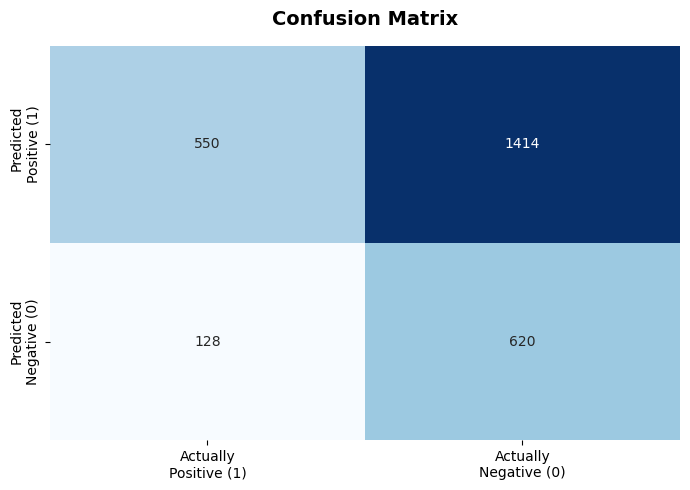

Classification Report — Validation Set
              precision    recall  f1-score   support

   Non-Donor       0.83      0.30      0.45      2034
       Donor       0.28      0.81      0.42       678

    accuracy                           0.43      2712
   macro avg       0.55      0.56      0.43      2712
weighted avg       0.69      0.43      0.44      2712



In [97]:
# Re-train the final model only on X_train for honest evaluation
final_model.fit(X_train_final, y_train)

# Predictions with the optimised threshold
y_val_proba = final_model.predict_proba(X_val_final)[:, 1]
y_val_pred  = (y_val_proba >= best_threshold).astype(int)

# Build val_results (used in subsequent error profile cells)
val_results = X_val_final.copy()
val_results['actual']      = y_val.values
val_results['predicted']   = y_val_pred
val_results['probability'] = y_val_proba

def categorize_error(row):
    if row['actual'] == 1 and row['predicted'] == 1: return 'True Positive (TP)'
    if row['actual'] == 0 and row['predicted'] == 0: return 'True Negative (TN)'
    if row['actual'] == 1 and row['predicted'] == 0: return 'False Negative (FN)'
    return 'False Positive (FP)'

val_results['error_category'] = val_results.apply(categorize_error, axis=1)

# Confusion Matrix (transposed: Predicted on rows, Actual on columns)
cm = confusion_matrix(y_val, y_val_pred, labels=[1, 0])
cm = cm.T

fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Actually\nPositive (1)', 'Actually\nNegative (0)'],
            yticklabels=['Predicted\nPositive (1)', 'Predicted\nNegative (0)'],
            ax=ax)
ax.set_title('Confusion Matrix', fontsize=14, fontweight='bold', pad=15)
plt.tight_layout()
plt.show()

# Classification Report
print("=" * 60)
print("Classification Report — Validation Set")
print("=" * 60)
print(classification_report(y_val, y_val_pred, target_names=['Non-Donor', 'Donor']))

The confusion matrix and classification report together provide a detailed breakdown of how the model performs on the validation set. Across  2,712 observations, the model correctly identifies 550 donors (True Positives) and 620 non-donors (True Negatives). At the same time, it generated  1,414 false positives (non-donors are incorrectly marked as donors), and 128 false negatives (actual donors that the model missed).

False positives occur 11 times more often than false negatives. This imbalance is a direct result of the modelling strategy. The use of `class_weight='balanced'` during training combine with a reduce decision threshold of 0.44 deliberately shifts the model toward capturing more true donors, accepting lower precision in exchange. The classification report highlights this trade-off clearly for both class:

- For the **donor class**, the model achieves a **recall of 0.81**, meaning it successfully detectes around 8 out of every 10 donors. However, its  **precision of 0.28**, indicating that only about 3 in 10 predicted donors are truly donors, the remaining 7 are false positives.
- For the **non-donor class**, the situation is reversed: a **precision of 0.83**, so predictions of non-donors are generally realiable but a **recall of only 0.30**, meaning the model correctly identifies only about 3 in 10 non-donors.

This asymmetry is intentional and reflects the different real-world consequenced of each error type. 
- **A false negative** (missing a true donor) — represents a permanently lost donation opportunity: the individual is never contacted and cannot contribute in that campaign again. 
- **A false positive** (targeting a non-donor) - only results in a small, one-off outreach cost wiht no lasting downside. 

In donor-acquisition contexts, where contact costs are typically minimal compared to potential donation value,  **it is generally preferable contacting too many people than to miss a real donor**. As a result, the model is intentionally tuned toward higher recall.


The **macro average F1 score of 0.43** provides a balanced view across both classes, providing a more honest assessment than overall accuracy under class imbalance. Meanwhile, the **accuracy of 0.43** is not particuarly informative: because under a class imbalance, a naive classifier predicting "Non-Donor" for every observation would still achieve around  75% accuracy while failing to identify any donors at all. Therefore, the F1 score is a more meaningful metric, as it captures the trade-off between precision and recall and better reflects performance on the minority class of interest.

<h2 id = "p7-2" style="color:#006699;">7.2 Comparison of Feature Distribution</h2>

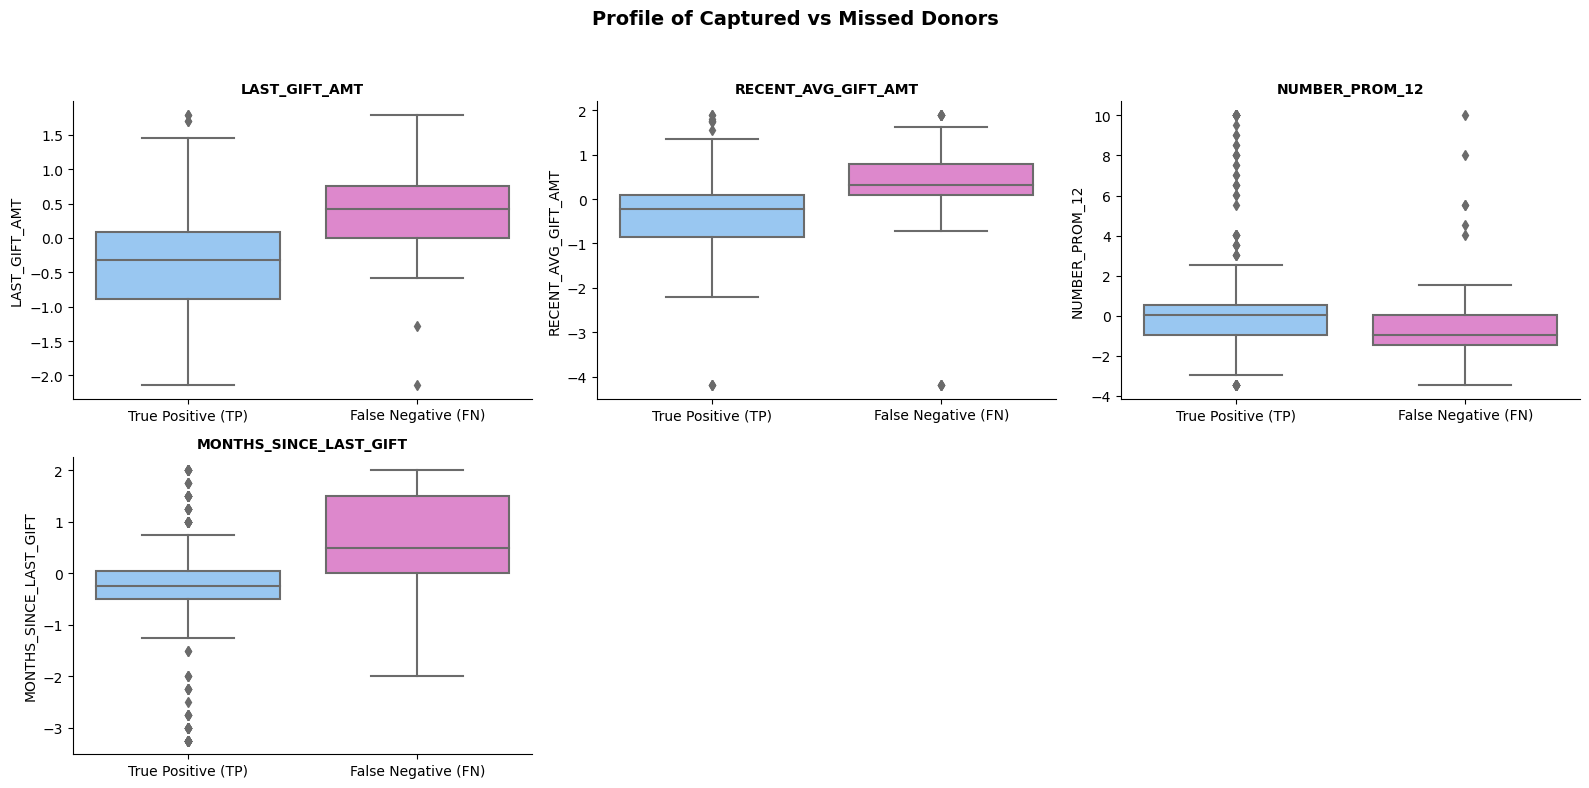

In [98]:
true_donors = val_results[val_results['actual'] == 1]

key_features = ['LIFETIME_GIFT_AMOUNT', 'LAST_GIFT_AMT', 'RECENT_AVG_GIFT_AMT',
                'LIFETIME_GIFT_COUNT', 'NUMBER_PROM_12', 'MONTHS_SINCE_LAST_GIFT']
key_features = [col for col in key_features if col in val_results.columns]

n_cols = 3
n_rows = -(-len(key_features) // n_cols)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, n_rows * 4))
axes = axes.flatten()

for i, col in enumerate(key_features):
    sns.boxplot(data=true_donors, x='error_category', y=col, ax=axes[i],
                palette={'True Positive (TP)': '#8BC7FF', 'False Negative (FN)': '#EB7AD4'})
    axes[i].set_title(f'{col}', fontsize=10, fontweight='bold')
    axes[i].set_xlabel('')
    axes[i].spines[['top', 'right']].set_visible(False)

for j in range(len(key_features), len(axes)):
    axes[j].set_visible(False)

plt.suptitle('Profile of Captured vs Missed Donors', fontsize=14, fontweight='bold')
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

The four features included in this analysis were selected because they reflected the three core dimensions of the **RFM analysis** (Recency, Frequency, Monetary). In particuarly, `MONTHS_SINCE_LAST_GIFT` represents *Recency*, `NUMBER_PROM_12` represents *Frequency* of recent campaign exposure, and both `LAST_GIFT_AMT` and `RECENT_AVG_GIFT_AMT` reflect the *Monetary* dimension. Using these variables allows a meaningful behavioural comparison between donors correctly identified by the model (True Positives) and those it missed (False Negatives).

The missed donors (False Negatives) generally show **higher recent donation amounts** (`LAST_GIFT_AMT` and `RECENT_AVG_GIFT_AMT`) compared to True Positives. In contrast, True Positives rend to have lower and more dispersed donation amounts, suggesting that the model is more effective at identifying donors with modest financial histories than those with stronger monetary profiles.

Looking at recency, False Negatives show **higher values of `MONTHS_SINCE_LAST_GIFT`**, meaning they have not donated as recently as the correctly identified donors. True Positives, on the other hand, are more recent donors, indicating that the model reliance on recent activey when identifying likely donors. As the result, the model struggles with donors who previously donated but have since become less active.

The pattern in `NUMBER_PROM_12` shows that the captured donors (True Positives) received slightly more promotions than the missed donors. This suggests that campaign exposure has a modest influence on whether a donor is correctly identified, but it is not the strongest differentiator between the two groups.

Overall, these results indicate that the False Negatives are **previously valuable but recently inactive donors**. They typically have higher historical donation amounts but longer gaps since their last contribution, along with slightly lower recent campaign exposure. This highlights a limitation of the model: it may benefit from additional features that better capture **long-term donor value beyond short-term recency signals**.

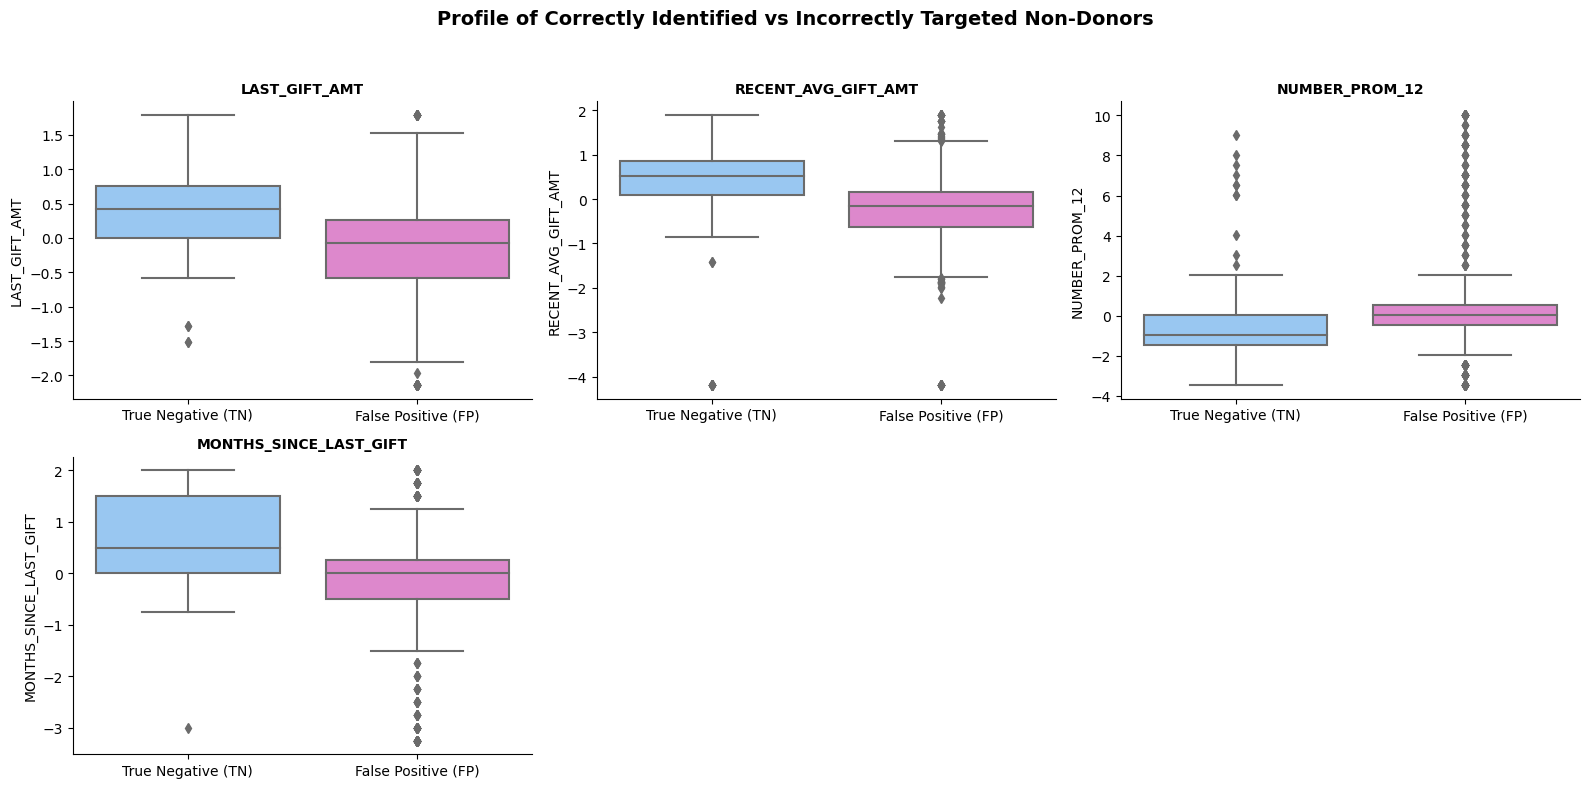

In [99]:
# Filter only to non-donors (TN and FP)
true_non_donors = val_results[val_results['actual'] == 0]

key_features = ['LIFETIME_GIFT_AMOUNT', 'LAST_GIFT_AMT', 'RECENT_AVG_GIFT_AMT',
                'LIFETIME_GIFT_COUNT', 'NUMBER_PROM_12', 'MONTHS_SINCE_LAST_GIFT']
key_features = [col for col in key_features if col in val_results.columns]

n_cols = 3
n_rows = -(-len(key_features) // n_cols)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, n_rows * 4))
axes = axes.flatten()

for i, col in enumerate(key_features):
    sns.boxplot(data=true_non_donors, x='error_category', y=col, ax=axes[i],
                palette={'True Negative (TN)': '#8BC7FF', 'False Positive (FP)': '#EB7AD4'})
    axes[i].set_title(f'{col}', fontsize=10, fontweight='bold')
    axes[i].set_xlabel('')
    axes[i].spines[['top', 'right']].set_visible(False)

for j in range(len(key_features), len(axes)):
    axes[j].set_visible(False)

plt.suptitle('Profile of Correctly Identified vs Incorrectly Targeted Non-Donors',
             fontsize=14, fontweight='bold')
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

The same RFM-based comparison is now applied within the non-donor class, contrasting the True Negatives (correctly identified non-donors) with the False Positive (non-donors incorrectly flagged as donors). The results reveal a clear and interpretable behavioural pattern behind these misclassifications.


True Negatives generally exhibit **higher values of `LAST_GIFT_AMT` and `RECENT_AVG_GIFT_AMT`** than the False Positives, as well as **higher values of `MONTHS_SINCE_LAST_GIFT`**, indicating they donated larger amounts but less recently. In contrast, False Positives tend to have lower donation amounts but more recent activity and received slightly more promotions in the last 12 months. From the model’s perspective, this stronger recency signal is often sufficient to shift predictions toward the donor class, even when monetary indicators are weaker.

This pattern provides an important practical insight. Many False Positives are not random errors: they are **individuals who genuinely "look like" donors from a behavioural standpoint**. They recently active and engaged with the organization's outreach, but they did not respond to the campaign captured by the target variable. From a marketing perspective, these individuals are not necessarily bad targets, as their recency profile suggests continued interest and potential responsiveness in future outreach.


When combined with the previous analysis of False Negatives, this findings show that the model's errors follow consistent behavioural logic. False Negatives tend to be **historically valuable but recently dormant**, while False Positives tend to be **recently active but with lower monetary contribution amounts**. Overall, these insights highlight a limitations of relying exclusively on RFM-based features and suggest that incorporating additional information, such as long-term donor value or engagement trajectories over time, could improve the model's discriminative power.